# Kenya Land Valuation: Exploratory Data Analysis

This is **Notebook 2 of 3** in the Kenya land price project. It is **descriptive only**: it reads the engineered listings (`kenya_land_engineered_final.parquet`) and the Kenya county boundaries (`kenya_counties.gpkg`), draws 27 charts and writes three summary-statistics CSV tables, saving everything to `outputs/eda`, and does not modify any data. Feature selection decisions are **not** made here — they belong to Notebook 3 (modelling), where candidate feature sets are compared by cross-validation; this notebook only describes and visualises what is in the data.

**Inputs** — `kenya_land_engineered_final.parquet` (listings engineered by Notebook 1) and `kenya_counties.gpkg` (layer `ADM_ADM_1`, county boundaries downloaded by Notebook 1). **Outputs** — 27 chart PNGs and 3 summary CSV tables in `outputs/eda` on Google Drive. **How to run** — run the cells in order on Google Colab with Google Drive mounted (Cell 1.1 mounts Drive, creates the `outputs/eda` folder and sets the chart style; Cell 1.3 defines the analysis settings such as `MIN_COUNTY_N`; every chart cell saves its PNG to Drive as well as displaying it inline).

**Best practice principles applied throughout this notebook:**
- One chart per cell — no facets or grouped panels
- Titles are descriptive or computed from the data
- Colour is used intentionally: sequential for continuous values, diverging for correlations
- Annotations guide the reader to the most important finding on each chart
- Log-transformed axes are used only where the data is right-skewed and the raw scale hides variation
- Every chart answers one specific question, stated clearly in the markdown before the code

| Cell | Chart | Question answered |
|---|---|---|
| 2.1 | Missing values per feature | How much is missing in each column, and where does missingness concentrate? |
| 2.2 | Target distribution | What does the price target look like before and after the outlier clip? |
| 2.3 | Listings per county | How many listings support each county's statistics? |
| 2.4 | Data-source mix | Where do the geocode, size and price values come from? |
| 2.5 | Summary statistics tables | What are the headline numbers overall, by county and by property type? |
| 3.1 | Geospatial scatter | Where is land expensive and where are large plots? |
| 3.2 | Choropleth (median) | Which counties have the highest median land prices? |
| 3.3 | Top and bottom counties | Which counties are most and least expensive at the median? |
| 3.4 | Smoothed price surface | What does the continuous land value landscape look like? |
| 3.5 | Illustrative investment ranking | Which counties balance price, services and access best? |
| 4.1 | Nairobi distance vs price | How steeply does price fall as you move away from Nairobi? |
| 4.2 | Reference city distance vs price | Does the local reference city matter beyond Nairobi's pull? |
| 4.3 | County-town distance vs price | Does the county-town distance matter beyond Nairobi and the reference city? |
| 4.4 | Water-body distance flag vs price | Do listings with a measured water-body distance differ in price? |
| 5.1 | Amenities score distribution | How are amenities scores distributed across listings? |
| 5.2 | Accessibility score distribution | How are accessibility scores distributed across listings? |
| 5.3 | Infrastructure score distribution | How are infrastructure scores distributed across listings? |
| 5.4 | Price by score quintile | Do higher service scores go with higher prices? |
| 5.5 | Score correlations | How strongly are the three service scores related to each other? |
| 5.6 | Scores by county | How do service scores vary across the largest counties? |
| 5.7 | Geographic-only vs text-boosted scores | How different are the geographic-only scores from the text-boosted ones? |
| 5.8 | Parcel features mentioned in listings | How often is each parcel feature mentioned, and how often was the infrastructure score imputed? |
| 6.1 | Size vs price (log-log) | Do larger parcels cost more per acre or less? |
| 6.2 | Size distribution | How are parcel sizes distributed? |
| 6.3 | Price by size band | How does price per acre change across size bands? |
| 7.1 | Correlation matrix (Spearman) | Which features move together with price, and which with each other? |
| 7.2 | Mutual information | Which features share the most information with log price? |
| 7.3 | Redundant pairs | Which feature pairs are so correlated that one may be redundant? |


## Contents

- [Phase 1 — Setup and Data](#phase-1)
  - [Cell 1.1 — Setup](#cell-1-1)
  - [Cell 1.2 — Load and Prepare Data](#cell-1-2)
  - [Cell 1.3 — Analysis Settings](#cell-1-3)

- [Phase 2 — Data Quality and Descriptive Statistics](#phase-2)
  - [Cell 2.1 — Missing Values per Feature](#cell-2-1)
  - [Cell 2.2 — Target Distribution](#cell-2-2)
  - [Cell 2.3 — Listings per County](#cell-2-3)
  - [Cell 2.4 — Data-Source Mix](#cell-2-4)
  - [Cell 2.5 — Summary Statistics Tables](#cell-2-5)

- [Phase 3 — Spatial Patterns](#phase-3)
  - [Cell 3.1 — Where Is Land Expensive and Where Are the Largest Plots in Kenya?](#cell-3-1)
  - [Cell 3.2 — County Choropleth: Median Price per Acre](#cell-3-2)
  - [Cell 3.3 — Highest and Lowest County Medians](#cell-3-3)
  - [Cell 3.4 — Smoothed Price Surface](#cell-3-4)
  - [Cell 3.5 — Illustrative Investment Ranking of Counties](#cell-3-5)

- [Phase 4 — Distance Effects](#phase-4)
  - [Cell 4.1 — Land Price Decays Exponentially as Distance from Nairobi Increases](#cell-4-1)
  - [Cell 4.2 — Local Reference City Proximity Also Drives Price, Especially Outside Nairobi's Reach](#cell-4-2)
  - [Cell 4.3 — County-Town Distance vs Price per Acre](#cell-4-3)
  - [Cell 4.4 — Water-Body Distance Flag vs Price per Acre](#cell-4-4)

- [Phase 5 — Service Scores](#phase-5)
  - [Cell 5.0 — Score Distribution Histograms (Shared Helper)](#cell-5-0)
  - [Cell 5.1 — Distribution of Amenities Scores Across All Listings](#cell-5-1)
  - [Cell 5.2 — Distribution of Accessibility Scores Across All Listings](#cell-5-2)
  - [Cell 5.3 — Distribution of Infrastructure Scores Across All Listings](#cell-5-3)
  - [Cell 5.4 — Median Price by Score Quintile](#cell-5-4)
  - [Cell 5.5 — Spearman Correlations Between Service Scores](#cell-5-5)
  - [Cell 5.6 — Service Scores by County](#cell-5-6)
  - [Cell 5.7 — Geographic-Only vs Text-Boosted Scores](#cell-5-7)
  - [Cell 5.8 — Parcel Features Mentioned in Listings](#cell-5-8)

- [Phase 6 — Size and Price Structure](#phase-6)
  - [Cell 6.1 — Larger Parcels Cost More in Total but Less per Acre — The Bulk Discount Effect](#cell-6-1)
  - [Cell 6.2 — Parcel Size Distribution](#cell-6-2)
  - [Cell 6.3 — Price per Acre by Size Band](#cell-6-3)

- [Phase 7 — Feature Relationships](#phase-7)
  - [Cell 7.1 — Correlation Matrix: Spearman, Pairwise-Complete](#cell-7-1)
  - [Cell 7.2 — Mutual Information with Log Price](#cell-7-2)
  - [Cell 7.3 — Redundant Feature Pairs](#cell-7-3)

- [Phase 8 — Completion Check](#phase-8)
  - [Cell 8.1 — EDA Complete](#cell-8-1)


## Inputs, Outputs and Sample Used

**Flow:**

```text
Notebook 1  ->  kenya_land_engineered_final.parquet + kenya_counties.gpkg
                    |
                    v
              Notebook 2 (this notebook)  ->  27 chart PNGs + 3 summary CSVs in outputs/eda
```

Feature selection decisions belong to Notebook 3 (modelling), where they are validated by cross-validation; this notebook is descriptive only.

**Inputs (read only — this notebook does not modify any data):**

| Input file | Folder variable | Created in Notebook 1 |
|---|---|---|
| `kenya_land_engineered_final.parquet` | `INTERIM_DATA` (`data/interim`) | Phase 8 — Derived Columns and Final Assembly, Cell 8.3 (final save) |
| `kenya_counties.gpkg` (layer `ADM_ADM_1`) | `OSM_DATA` (`data/osm`) | Phase 4 — Proximity Features, county-correction part (Cells 4.8–4.14), Cell 4.9 (downloaded once from GADM if not already on Drive) |

**Sample used:**

- Cell 1.2 keeps every listing with a valid `size_acres` and `price_per_acre` (both present and > 0). This **unclipped** sample is stored as `df_all` and is the sample the **Phase 2 data-quality charts (Cells 2.1–2.5)** describe.
- Cell 1.2 then removes listings below the 1st or above the 99th percentile of `price_per_acre` (percentiles computed inside Cell 1.2 on the valid sample). This **clipped** sample `df` is what Phases 3–7 chart; `gdf` is its geocoded subset, used by the map cells 3.1 and 3.4. Both sample sizes are printed by Cell 1.2 at run time.
- The modelling notebook (Notebook 3) applies its own row filters, so its modelling sample is defined independently of this EDA sample.

**Outputs and cell register** — every chart is saved by `plt.savefig` to `OUTPUTS` (`outputs/eda`) and every table by `.to_csv`; file names are copied exactly from the save calls.

| Cell | Question answered | Previous label | Output file |
|---|---|---|---|
| 1.1 | – (environment setup) | Cell 0 | – |
| 1.2 | – (loads and prepares the sample) | Cell 1 | – |
| 1.3 | – (analysis settings and column check) | – (new) | – |
| 2.1 | How much is missing in each column, and where does missingness concentrate? | – (new) | `chart9_missing_values.png` |
| 2.2 | What does the price target look like before and after the outlier clip? | – (new) | `chart10_target_distribution.png` |
| 2.3 | How many listings support each county's statistics? | – (new) | `chart11_listings_per_county.png` |
| 2.4 | Where do the geocode, size and price values come from? | – (new) | `chart12_data_source_mix.png` |
| 2.5 | What are the headline numbers overall, by county and by property type? | – (new) | `summary_statistics_overall.csv`, `summary_statistics_by_county.csv`, `summary_statistics_by_property_type.csv` |
| 3.1 | Where is land expensive and where are large plots? | Chart 1 | `chart1_geospatial_scatter.png` |
| 3.2 | Which counties have the highest median land prices? | Chart 2 | `chart2_choropleth_median_price.png` |
| 3.3 | Which counties are most and least expensive at the median? | – (new) | `chart13_top_bottom_counties.png` |
| 3.4 | What does the continuous land value landscape look like? | Chart 5 | `chart5_smoothed_price_surface.png` |
| 3.5 | Which counties balance price, services and access best? | Chart 6 | `chart6_top5_investment_counties.png` |
| 4.1 | How steeply does price fall as you move away from Nairobi? | Chart 3A | `chart3a_nairobi_distance.png` |
| 4.2 | Does the local reference city matter beyond Nairobi's pull? | Chart 3B | `chart3b_town_distance.png` |
| 4.3 | Does the county-town distance matter beyond Nairobi and the reference city? | – (new) | `chart14_county_town_distance.png` |
| 4.4 | Do listings with a measured water-body distance differ in price? | – (new) | `chart15_water_body_indicator.png` |
| 5.0 | How is this composite score distributed across all listings? | Charts 4A–4C | – |
| 5.1 | How are amenities scores distributed across listings? | Chart 4A | `chart4a_amenities_score.png` |
| 5.2 | How are accessibility scores distributed across listings? | Chart 4B | `chart4b_accessibility_score.png` |
| 5.3 | How are infrastructure scores distributed across listings? | Chart 4C | `chart4c_infrastructure_score.png` |
| 5.4 | Do higher service scores go with higher prices? | – (new) | `chart16_price_by_score_band.png` |
| 5.5 | How strongly are the three service scores related to each other? | – (new) | `chart17_score_correlation.png` |
| 5.6 | How do service scores vary across the largest counties? | – (new) | `chart18_scores_by_county.png` |
| 5.7 | How different are the geographic-only scores from the text-boosted ones? | – (new) | `chart23_scores_boosted_vs_geographic.png` |
| 5.8 | How often is each parcel feature mentioned, and how often was the infrastructure score imputed? | – (new) | `chart24_parcel_feature_prevalence.png` |
| 6.1 | Do larger parcels cost more per acre or less? | Chart 7 | `chart7_size_vs_price_loglog.png` |
| 6.2 | How are parcel sizes distributed? | – (new) | `chart19_size_distribution.png` |
| 6.3 | How does price per acre change across size bands? | – (new) | `chart20_price_by_size_band.png` |
| 7.1 | Which features move together with price, and which with each other? | Chart 8 | `chart8_correlation_matrix.png` |
| 7.2 | Which features share the most information with log price? | – (new) | `chart21_mutual_information.png` |
| 7.3 | Which feature pairs are so correlated that one may be redundant? | – (new) | `chart22_redundant_pairs.png` |
| 8.1 | – (completion check) | EDA Complete | – |

**Old files kept:** the previous `chart2_choropleth_mean_price.png` (mean choropleth) and `chart5_idw_price_surface.png` (IDW surface) stay in `outputs/eda`; Cells 3.2 and 3.4 now write `chart2_choropleth_median_price.png` and `chart5_smoothed_price_surface.png` instead, and no old file is deleted.


<a id="phase-1"></a>

## Phase 1 — Setup and Data

This phase mounts Google Drive, sets up the libraries, folder paths and chart style, loads the engineered listings and the county boundaries, and prepares the samples and settings that every later chart uses.

<a id="cell-1-1"></a>

### Cell 1.1 — Setup

Mounts Google Drive, imports the libraries (including `scipy.stats` and scikit-learn's `mutual_info_regression`, used by the cells added in this revision), defines the folder paths, the colour palette and the global chart style, and creates `outputs/eda` if it does not exist.


In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import seaborn as sns
import geopandas as gpd
from statsmodels.nonparametric.smoothers_lowess import lowess
import scipy.stats as stats
from sklearn.feature_selection import mutual_info_regression
warnings.filterwarnings("ignore")

PROJECT_ROOT = "/content/drive/MyDrive/kenya_land_valuation"
INTERIM_DATA = f"{PROJECT_ROOT}/data/interim"
OSM_DATA     = f"{PROJECT_ROOT}/data/osm"
OUTPUTS      = f"{PROJECT_ROOT}/outputs/eda"
os.makedirs(OUTPUTS, exist_ok=True)

# Colour palette — intentional and consistent across all charts
BLUE   = "#2E6DA4"
ORANGE = "#E8A838"
DARK   = "#1B3A5C"
GREEN  = "#2E8B57"
RED    = "#D9534F"
GREY   = "#888888"
LIGHT  = "#f5f5f5"

# Global style — clean, minimal, publication-ready
plt.rcParams.update({
    "figure.facecolor" : "white",
    "axes.facecolor"   : "white",
    "axes.spines.top"  : False,
    "axes.spines.right": False,
    "font.family"      : "DejaVu Sans",
    "axes.titlesize"   : 14,
    "axes.labelsize"   : 11,
    "axes.titlepad"    : 12,
    "xtick.labelsize"  : 9,
    "ytick.labelsize"  : 9,
})

print("Setup complete.")


<a id="cell-1-2"></a>

### Cell 1.2 — Load and Prepare Data

Reads the engineered parquet, keeps listings with a valid `size_acres` and `price_per_acre` (both present and positive) and stores that **unclipped** sample as `df_all` — the sample the Phase 2 data-quality charts describe. It then removes listings below the 1st and above the 99th percentile of `price_per_acre` (the clipped sample `df`, used by Phases 3–7), builds the log columns, loads the county boundaries, builds `gdf` (the geocoded listings) and the county price aggregates `county_stats` / `counties_plot`, and defines the five city reference points.


In [ ]:
df = pd.read_parquet(f"{INTERIM_DATA}/kenya_land_engineered_final.parquet")

df = df[
    df["size_acres"].notna()     & (df["size_acres"]     > 0) &
    df["price_per_acre"].notna() & (df["price_per_acre"] > 0)
].copy().reset_index(drop=True)

# Unclipped sample — valid price and size, kept for the Phase 2 data-quality charts
df_all = df.copy()

# Clip outliers at 1st and 99th percentile
p01 = df["price_per_acre"].quantile(0.01)
p99 = df["price_per_acre"].quantile(0.99)
df  = df[(df["price_per_acre"] >= p01) & (df["price_per_acre"] <= p99)].copy().reset_index(drop=True)

# Log-transformed columns used in proximity and size charts
df["log_price_per_acre"] = np.log(df["price_per_acre"])
df["log_size_acres"]     = np.log(df["size_acres"].clip(lower=0.001))

# County shapefile
counties_gdf = gpd.read_file(f"{OSM_DATA}/kenya_counties.gpkg", layer="ADM_ADM_1")
counties_gdf = counties_gdf[["NAME_1","geometry"]].rename(columns={"NAME_1":"county"}).to_crs("EPSG:4326")

# GeoDataFrame of listings
geo_df = df[df["latitude"].notna() & df["longitude"].notna()].copy()
gdf    = gpd.GeoDataFrame(geo_df,
             geometry=gpd.points_from_xy(geo_df["longitude"], geo_df["latitude"]),
             crs="EPSG:4326")

# County price aggregates
county_stats = (df.groupby("county")["price_per_acre"]
                  .agg(mean_ppa="mean", median_ppa="median", count="count")
                  .reset_index())
counties_plot = counties_gdf.merge(county_stats, on="county", how="left")

# Major city reference points
CITIES = {
    "Nairobi" : (-1.2921, 36.8219),
    "Mombasa" : (-4.0435, 39.6682),
    "Kisumu"  : (-0.1022, 34.7617),
    "Nakuru"  : (-0.3031, 36.0800),
    "Eldoret" : ( 0.5143, 35.2698),
}

print(f"Listings ready for EDA : {len(df):,}")
print(f"Unclipped sample       : {len(df_all):,}")
print(f"With coordinates       : {len(gdf):,}")
print(f"Counties with data     : {county_stats['county'].nunique()}")


<a id="cell-1-3"></a>

### Cell 1.3 — Analysis Settings

Defines the constants used by the cells added in this revision: the random seed, the minimum number of listings a county needs before it is coloured or ranked in any county chart (`MIN_COUNTY_N` — smaller counties are greyed or hidden, and their n is always shown), and the tuning knobs for the smoothed surface and the mutual-information run. The cell also verifies that every column this notebook uses is present in the parquet, and fails with a clear message if the engineered dataset from Notebook 1 is missing a column.


In [ ]:
# ---- Analysis settings shared by the cells added in this revision ----
SEED = 42                     # base random seed; Cell 7.2 uses SEED .. SEED+N_MI_SEEDS-1
MIN_COUNTY_N = 10             # counties with fewer listings are greyed or hidden in
                              # every county chart, with n shown
TOP_COUNTIES = 8              # counties shown in the grouped score boxplots (Cell 5.6)
N_MI_SEEDS = 5                # mutual-information repeats (Cell 7.2)
SMOOTH_H_OVERRIDE_KM = None   # manual bandwidth override in km for Cell 3.4;
                              # None = choose h by leave-one-out cross-validation
SMOOTH_GRID_RES = 600         # price-surface grid resolution, cells per axis (Cell 3.4)
REDUNDANT_TOP_PAIRS = 15      # strongest feature pairs plotted (Cell 7.3)

# Every column this notebook uses must exist in the engineered parquet.
REQUIRED_COLUMNS = [
    "county", "latitude", "longitude", "size_acres", "price_per_acre",
    "prop_type", "geocode_source", "size_source", "price_flag",
    "dist_to_nairobi_km", "dist_to_county_town_km", "reference_city",
    "reference_city_dist_km", "dist_to_water_body_km", "geocode_confidence",
    "amenities_score", "accessibility_score", "infrastructure_score",
    # Round 3 EDA update: the model and the app use the geographic-only
    # scores; the ten 0/1 infra_<item> columns underlie infrastructure_score
    # and are charted by Cell 5.8.
    "amenities_score_osm", "accessibility_score_osm", "infra_source",
    "infra_borehole", "infra_piped_water", "infra_river_water",
    "infra_water_tank", "infra_grid_electric", "infra_solar_electric",
    "infra_full_fence", "infra_partial_fence", "infra_structures",
    "infra_internal_road",
]
_missing = [c for c in REQUIRED_COLUMNS if c not in df_all.columns]
if _missing:
    raise ValueError(
        f"Missing expected column(s) in the parquet: {_missing}. This notebook "
        "requires the engineered dataset produced by Notebook 1 "
        "(kenya_land_engineered_final.parquet)."
    )

print("Analysis settings:")
print(f"  SEED                  = {SEED}")
print(f"  MIN_COUNTY_N          = {MIN_COUNTY_N}   (counties below this are greyed or hidden in county charts, n always shown)")
print(f"  TOP_COUNTIES          = {TOP_COUNTIES}")
print(f"  N_MI_SEEDS            = {N_MI_SEEDS}")
print(f"  SMOOTH_H_OVERRIDE_KM  = {SMOOTH_H_OVERRIDE_KM}")
print(f"  SMOOTH_GRID_RES       = {SMOOTH_GRID_RES}")
print(f"  REDUNDANT_TOP_PAIRS   = {REDUNDANT_TOP_PAIRS}")
print(f"Column check: all {len(REQUIRED_COLUMNS)} required columns present in the parquet.")


<a id="phase-2"></a>

## Phase 2 — Data Quality and Descriptive Statistics

This phase audits the data before any interpretation: how much is missing per feature, what the price target looks like before outlier clipping, how many listings support each county, where the values come from, and the headline summary tables.

<a id="cell-2-1"></a>

### Cell 2.1 — Missing Values per Feature

**Question:** How much is missing in each column, and where does missingness concentrate?

**How to read:** Bars show the share of listings with a null value per column, on the unclipped sample (`df_all`); the count of missing listings is at the end of each bar. Orange bars exceed the 5% reference line. `dist_to_water_body_km` is null by design for about 96% of listings (only counties bordering a water body get a distance) — which is why the later cells use a `has_water_body_distance` flag instead of the raw distance.


In [ ]:
# Missing values per feature — all columns of the unclipped sample (df_all)
miss_pct = (df_all.isna().mean() * 100).sort_values()
n_rows_all = len(df_all)
above_5 = miss_pct[miss_pct > 5]

fig, ax = plt.subplots(figsize=(13, max(8, 0.34 * len(miss_pct) + 2)))

bar_colors = [ORANGE if v > 5 else BLUE for v in miss_pct.values]
bars = ax.barh(miss_pct.index, miss_pct.values, color=bar_colors,
               height=0.72, zorder=2)

# Count label at the end of every bar
for bar, (col, v) in zip(bars, miss_pct.items()):
    n_missing = int(df_all[col].isna().sum())
    ax.text(bar.get_width() + 0.8, bar.get_y() + bar.get_height() / 2,
            f"{v:.1f}%  (n={n_missing:,})", va="center", fontsize=8.5, color=DARK)

# 5% reference line — columns above it are marked in orange
ax.axvline(5, color=RED, linewidth=1.4, linestyle="--", alpha=0.85, zorder=3)
ax.text(5.6, 0.02, "5% threshold", fontsize=9, color=RED, va="bottom",
        transform=ax.get_xaxis_transform())   # x in data units, y in axes fraction

ax.set_title(
    f"Missing Values per Feature — {len(above_5)} of {len(miss_pct)} Columns Exceed 5% Missing\n"
    f"All columns of the unclipped sample (n={n_rows_all:,} listings); orange bars are above the 5% line",
    fontsize=13, fontweight="bold"
)
ax.set_xlabel("Share of listings missing (%)", fontsize=11)
ax.set_ylabel("Column", fontsize=11)
ax.set_xlim(0, max(miss_pct.max() * 1.24, 8))
ax.tick_params(axis="y", labelsize=8.5)
ax.grid(axis="x", alpha=0.25, zorder=1)

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/chart9_missing_values.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: chart9_missing_values.png  |  n rows={n_rows_all:,}")
print(f"Columns above 5% missing: {list(above_5.index)}")


<a id="cell-2-2"></a>

### Cell 2.2 — Target Distribution

**Question:** What does the price-per-acre target look like before and after the outlier clip that Cell 1.2 applies?

**How to read:** The histogram shows log price per acre on the unclipped sample (`df_all`); the x axis is labelled in KSh. The dashed lines mark the 1st and 99th percentiles, and the legend counts how many listings sit in each clipped tail — those are the rows Cell 1.2 removes. The note in the corner compares the skewness of the raw and the log-transformed target: the log transform is what makes the distribution roughly symmetric.


In [ ]:
# Target distribution — log price per acre on the unclipped sample (df_all)
ppa_all     = df_all["price_per_acre"]
log_ppa_all = np.log(ppa_all)

p01_all, p50_all, p99_all = ppa_all.quantile([0.01, 0.50, 0.99])
n_low  = int((ppa_all <  p01_all).sum())
n_high = int((ppa_all >  p99_all).sum())
n_mid  = int(((ppa_all >= p01_all) & (ppa_all <= p99_all)).sum())

skew_raw = stats.skew(ppa_all)
skew_log = stats.skew(log_ppa_all)

fig, ax = plt.subplots(figsize=(13, 7))
ax.hist(log_ppa_all, bins=40, color=BLUE, alpha=0.72,
        edgecolor="white", linewidth=0.6, zorder=2)

ax.axvline(np.log(p01_all), color=RED,    linewidth=1.8, linestyle="--", zorder=4,
           label=f"1st percentile — {n_low:,} listings below (clipped by Cell 1.2)")
ax.axvline(np.log(p50_all), color=ORANGE, linewidth=1.8, linestyle=":" , zorder=4,
           label=f"Median — KSh {p50_all/1e6:.1f}M per acre")
ax.axvline(np.log(p99_all), color=DARK,   linewidth=1.8, linestyle="--", zorder=4,
           label=f"99th percentile — {n_high:,} listings above (clipped by Cell 1.2)")
ax.legend(fontsize=9.5, loc="upper left")

# X axis in KSh (the histogram is over log prices) — round 1-2-5 values per
# decade covering the plotted data (never below 1,000 KSh, so no two tick
# labels can coincide and no meaningless "0K" label can appear)
d_lo, d_hi = float(log_ppa_all.min()), float(log_ppa_all.max())
xt, xl = [], []
for k in range(3, 13):
    for m in (1.0, 2.0, 5.0):
        r = m * 10.0 ** k
        if not (d_lo <= np.log(r) <= d_hi):
            continue
        lab = f"KSh {r/1e6:.1f}M" if r >= 1e6 else f"KSh {r/1e3:.0f}K"
        if lab not in xl:
            xt.append(np.log(r)); xl.append(lab)
if not xt:
    xt, xl = ax.get_xticks(), [f"KSh {np.exp(v)/1e3:.0f}K" for v in ax.get_xticks()]
ax.set_xticks(xt)
ax.set_xticklabels(xl, fontsize=8.5)

# Skewness note — raw vs log target
ax.text(0.97, 0.72,
        f"Skewness\nraw price per acre : {skew_raw:+.2f}\nlog price per acre  : {skew_log:+.2f}",
        transform=ax.transAxes, ha="right", va="top", fontsize=10,
        fontfamily="monospace", color=DARK,
        bbox=dict(boxstyle="round,pad=0.45", facecolor="white",
                  alpha=0.92, edgecolor="#cccccc"))

ax.set_title(
    f"Target Distribution: Log Price per Acre (n={len(df_all):,} Unclipped Listings)\n"
    f"Cell 1.2 keeps the {n_mid:,} listings between the 1st and 99th percentiles; "
    f"skewness falls from {skew_raw:+.2f} (raw) to {skew_log:+.2f} (log)",
    fontsize=13, fontweight="bold"
)
ax.set_xlabel("Price per Acre — log scale (KSh equivalent)", fontsize=11)
ax.set_ylabel("Number of Listings", fontsize=11)

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/chart10_target_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: chart10_target_distribution.png")
print(f"Unclipped n={len(df_all):,} | clipped tails: {n_low:,} below the 1st, "
      f"{n_high:,} above the 99th percentile | kept: {n_mid:,}")
print(f"Skewness: raw {skew_raw:+.2f} vs log {skew_log:+.2f}")


<a id="cell-2-3"></a>

### Cell 2.3 — Listings per County

**Question:** How many listings actually support each county's statistics?

**How to read:** Bars show listing counts for the 20 counties with the most listings (unclipped sample), with the count on top of each bar. The dashed line is `MIN_COUNTY_N` from Cell 1.3: counties below it are drawn in orange, and the title counts how many of the counties in the data fall below the line. County-level medians computed from few listings are unstable — that is why Cells 3.2, 3.3 and 3.5 grey or exclude those counties.


In [ ]:
# Listings per county — how many listings stand behind each county's statistics
county_counts = df_all["county"].value_counts()
top20         = county_counts.head(20)
n_below       = int((county_counts < MIN_COUNTY_N).sum())
n_counties    = int(county_counts.size)

fig, ax = plt.subplots(figsize=(13, 7))
bars = ax.bar(range(len(top20)), top20.values, color=BLUE, width=0.72, zorder=2)
for i, v in enumerate(top20.values):          # counties below the threshold in orange
    if v < MIN_COUNTY_N:
        bars[i].set_color(ORANGE)

ax.set_xticks(range(len(top20)))
ax.set_xticklabels(top20.index, rotation=40, ha="right", fontsize=9)
for i, v in enumerate(top20.values):
    ax.text(i, v + top20.max() * 0.015, f"{v:,}", ha="center", fontsize=8.5, color=DARK)

ax.axhline(MIN_COUNTY_N, color=RED, linewidth=1.5, linestyle="--", zorder=3)
ax.text(len(top20) - 0.4, MIN_COUNTY_N + top20.max() * 0.02,
        f"MIN_COUNTY_N = {MIN_COUNTY_N}", ha="right", fontsize=9.5, color=RED)

ax.set_title(
    f"Listings per County — {n_below} of {n_counties} Counties Have Fewer Than "
    f"{MIN_COUNTY_N} Listings (Orange Bars)\n"
    f"Top {len(top20)} counties shown; counts from the unclipped sample (n={len(df_all):,})",
    fontsize=13, fontweight="bold"
)
ax.set_xlabel("County", fontsize=11)
ax.set_ylabel("Number of Listings", fontsize=11)
ax.set_ylim(0, top20.max() * 1.12)

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/chart11_listings_per_county.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: chart11_listings_per_county.png")
print(f"Counties with data: {n_counties} | below MIN_COUNTY_N={MIN_COUNTY_N}: "
      f"{n_below} | largest: {top20.index[0]} (n={int(top20.iloc[0]):,})")


<a id="cell-2-4"></a>

### Cell 2.4 — Data-Source Mix

**Question:** Where do the geocode, size and price values come from?

**How to read:** Each bar is one source column, stacked by the share of listings per category — the top 6 categories are shown individually, rarer ones are grouped as "Other", and nulls appear as "(missing)". A large "(missing)" or "Other" share is a reminder that the corresponding feature is partly inferred rather than observed, which matters when judging how much a model can learn from it.


In [ ]:
# Data-source mix — shares per source column (top 6 categories, rest as "Other")
source_cols = [
    ("geocode_source",    "Geocode source"),
    ("size_source",       "Size source"),
    ("price_flag",        "Price flag"),
]
FIXED_COLORS = {"(missing)": GREY, "Other": "#cccccc"}
BASE_COLORS  = [BLUE, ORANGE, GREEN, DARK, "#5BA3D9"]

shares_per_col, color_map = [], {}
for col, _label in source_cols:
    vc   = df_all[col].fillna("(missing)").value_counts()
    top  = vc.head(6)
    rest = vc.iloc[6:].sum()
    if rest > 0:
        top = pd.concat([top, pd.Series({"Other": rest})])
    shares_per_col.append(top / len(df_all) * 100)
    for cat in top.index:                     # stable colours across the three bars
        if cat not in color_map:
            if cat in FIXED_COLORS:
                color_map[cat] = FIXED_COLORS[cat]
            else:
                color_map[cat] = BASE_COLORS[len([c for c in color_map
                                                  if c not in FIXED_COLORS]) % len(BASE_COLORS)]

fig, ax = plt.subplots(figsize=(13, 5.6))
left = np.zeros(len(source_cols))
for k, shares in enumerate(shares_per_col):
    for cat, share in shares.items():
        ax.barh(k, share, left=left[k], color=color_map[cat], height=0.58,
                edgecolor="white", linewidth=0.6, zorder=2)
        if share >= 8:                        # inline labels only on wide segments
            ax.text(left[k] + share / 2, k, f"{cat}\n{share:.0f}%",
                    ha="center", va="center", fontsize=8, color="white",
                    fontweight="bold", zorder=3)
        left[k] += share

legend_order = []                             # one legend entry per category
for shares in shares_per_col:
    for cat in shares.index:
        if cat not in legend_order:
            legend_order.append(cat)
handles = [mpatches.Patch(facecolor=color_map[c], edgecolor="#888888",
                          linewidth=0.5, label=c) for c in legend_order]

ax.set_yticks(range(len(source_cols)))
ax.set_yticklabels([label for _c, label in source_cols], fontsize=11)
ax.set_xlim(0, 100)
ax.set_xlabel("Share of listings (%)", fontsize=11)
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4,
          fontsize=8.5, framealpha=0.95, edgecolor="#cccccc")

ax.set_title(
    f"Data-Source Mix — Shares per Source Column (n={len(df_all):,} Listings)\n"
    "Top 6 categories per column; rarer categories grouped as 'Other'; nulls shown as '(missing)'",
    fontsize=13, fontweight="bold"
)

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/chart12_data_source_mix.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: chart12_data_source_mix.png")
for (col, label), shares in zip(source_cols, shares_per_col):
    print(f"  {label}: " + ", ".join(f"{cat} {v:.1f}%" for cat, v in shares.items()))


<a id="cell-2-5"></a>

### Cell 2.5 — Summary Statistics Tables

**Question:** What are the headline numbers overall, by county and by property type?

**How to read:** Three tables on the unclipped sample: an overall `describe()` of the key numeric columns; the n, median and quartiles of price per acre for every county, with a flag column marking counties below `MIN_COUNTY_N`; and the same statistics by property type. All three tables are displayed and saved as CSV files in `outputs/eda`, and the completion check (Cell 8.1) verifies the files exist.


In [ ]:
# Summary statistics tables — overall, by county, by property type (unclipped sample)
num_cols = ["price_per_acre", "size_acres", "dist_to_nairobi_km",
            "dist_to_county_town_km", "reference_city_dist_km",
            "dist_to_water_body_km", "amenities_score",
            "accessibility_score", "infrastructure_score"]

overall = df_all[num_cols].describe().T
display(overall.round(2))
overall.to_csv(f"{OUTPUTS}/summary_statistics_overall.csv")
print("Saved: summary_statistics_overall.csv")

by_county = (df_all.groupby("county")["price_per_acre"]
             .agg(n="count",
                  median="median",
                  q1=lambda s: s.quantile(0.25),
                  q3=lambda s: s.quantile(0.75))
             .sort_values("median", ascending=False))
by_county["below_min_n"] = by_county["n"] < MIN_COUNTY_N
display(by_county)
by_county.to_csv(f"{OUTPUTS}/summary_statistics_by_county.csv")
print("Saved: summary_statistics_by_county.csv")

by_ptype = (df_all.groupby("prop_type")["price_per_acre"]
            .agg(n="count",
                 median="median",
                 q1=lambda s: s.quantile(0.25),
                 q3=lambda s: s.quantile(0.75))
            .sort_values("median", ascending=False))
display(by_ptype)
by_ptype.to_csv(f"{OUTPUTS}/summary_statistics_by_property_type.csv")
print("Saved: summary_statistics_by_property_type.csv")

n_small = int(by_county["below_min_n"].sum())
print(f"\nCounties flagged below MIN_COUNTY_N={MIN_COUNTY_N}: {n_small} of {len(by_county)}")


<a id="phase-3"></a>

## Phase 3 — Spatial Patterns

This phase maps where land is expensive across Kenya — as a scatter of listings, a county choropleth of median prices, a smoothed price surface, and an illustrative county ranking.

<a id="cell-3-1"></a>

### Cell 3.1 — Where Is Land Expensive and Where Are the Largest Plots in Kenya?

**Question:** Is there a geographic pattern linking high land prices to urban locations,
and do large parcels cluster away from cities as economic theory predicts?

**Best practice applied:**
- Size encodes a third variable (parcel size) without adding chart complexity
- Colour uses an intuitive sequential scale: red for expensive, green for cheap
- County boundaries provide geographic context without visual clutter
- City stars anchor the viewer spatially before they start reading the data points
- Colourbar labels show actual KSh values, not raw numbers

**How to interpret:** Red and orange dots near Nairobi and the coast confirm the urban land
price premium. Large dots (big parcels) appearing predominantly outside the dense clusters
around cities confirm that rural areas hold larger, cheaper land. Any large red dot far from
a city is a premium agricultural or tourism property worth investigating individually.


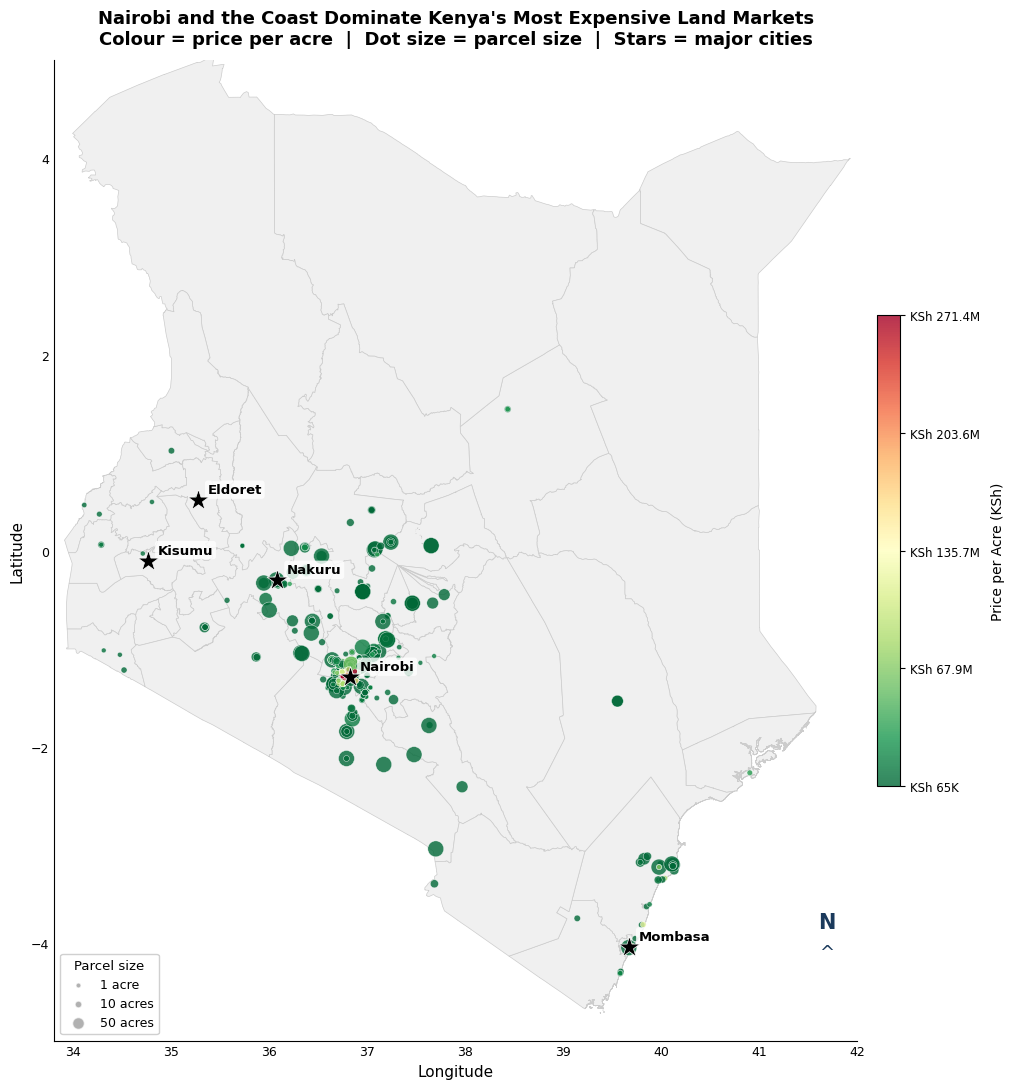

Saved: chart1_geospatial_scatter.png


In [4]:
import mapclassify

fig, ax = plt.subplots(figsize=(13, 11))

# Base layer — neutral grey county fills, minimal border
counties_gdf.plot(ax=ax, color="#f0f0f0", edgecolor="#cccccc", linewidth=0.5, zorder=1)

# Dot size proportional to parcel size — capped so ranches do not dominate
dot_sizes = np.clip(gdf["size_acres"], 0.1, 100)
dot_sizes = (dot_sizes / dot_sizes.max() * 120) + 12

# Price colour — clipped to 5th-95th percentile for maximum colour contrast
price_clip = gdf["price_per_acre"].clip(
    lower=gdf["price_per_acre"].quantile(0.05),
    upper=gdf["price_per_acre"].quantile(0.95)
)

sc = ax.scatter(
    gdf.geometry.x, gdf.geometry.y,
    c=price_clip, cmap="RdYlGn_r", s=dot_sizes,
    alpha=0.80, edgecolors="white", linewidths=0.35, zorder=3,
    norm=mcolors.Normalize(vmin=price_clip.quantile(0.05), vmax=price_clip.quantile(0.95))
)

# Colourbar — KSh labels, not raw numbers
cbar = plt.colorbar(sc, ax=ax, shrink=0.48, pad=0.015)
cbar.set_label("Price per Acre (KSh)", fontsize=10, labelpad=8)
tick_vals = np.linspace(price_clip.quantile(0.05), price_clip.quantile(0.95), 5)
cbar.set_ticks(tick_vals)
cbar.set_ticklabels(
    [f"KSh {v/1e6:.1f}M" if v >= 1e6 else f"KSh {v/1e3:.0f}K" for v in tick_vals],
    fontsize=8.5
)

# City markers — stars, bold labels, white halos for legibility
for city, (lat, lon) in CITIES.items():
    ax.scatter(lon, lat, marker="*", s=250, color="black",
               zorder=6, edgecolors="white", linewidths=0.5)
    ax.annotate(city, (lon, lat), textcoords="offset points", xytext=(7, 5),
                fontsize=9.5, fontweight="bold", color="black",
                bbox=dict(boxstyle="round,pad=0.2", facecolor="white",
                          alpha=0.80, edgecolor="none"))

# Parcel size legend
for sz_ac, lbl in [(1, "1 acre"), (10, "10 acres"), (50, "50 acres")]:
    s_scaled = (min(sz_ac, 100) / 100 * 120) + 12
    ax.scatter([], [], s=s_scaled, color=GREY, alpha=0.65,
               label=lbl, edgecolors="white")
ax.legend(title="Parcel size", loc="lower left",
          fontsize=9, title_fontsize=9.5, framealpha=0.92,
          edgecolor="#cccccc")

# North arrow
ax.annotate("N", xy=(0.962, 0.115), xycoords="axes fraction",
            fontsize=15, fontweight="bold", ha="center", color=DARK)
ax.annotate("^", xy=(0.962, 0.085), xycoords="axes fraction",
            fontsize=13, ha="center", color=DARK)

ax.set_title(
    "Nairobi and the Coast Dominate Kenya's Most Expensive Land Markets\n"
    "Colour = price per acre  |  Dot size = parcel size  |  Stars = major cities",
    fontsize=13, fontweight="bold"
)
ax.set_xlabel("Longitude", fontsize=11)
ax.set_ylabel("Latitude",  fontsize=11)
ax.set_xlim(33.8, 42.0)
ax.set_ylim(-5.0,  5.0)
ax.tick_params(which="both", length=0)

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/chart1_geospatial_scatter.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: chart1_geospatial_scatter.png")


<a id="cell-3-2"></a>

### Cell 3.2 — County Choropleth: Median Price per Acre

**Question:** Which counties have the highest median land prices, and how unequal is the geographic distribution of land value?

**Method:** Every county with at least `MIN_COUNTY_N` listings is coloured by the **median** price per acre (robust to the extreme listings that a mean still absorbs), classified with Fisher-Jenks natural breaks computed only on those counties. Counties with fewer listings are greyed and labelled with their n; counties with no listings are a separate grey. The mean-based aggregates from Cell 1.2 are kept in `county_stats` untouched.

**How to read:** Darker red = higher median price per acre. Grey counties are not "cheap" — they either have fewer than `MIN_COUNTY_N` listings (median unstable, shown as n) or no listings at all (median undefined). Compare counties through their labels (name, median, n) rather than by shade alone when their n values differ a lot, and read the three most expensive counties from the printout under the chart, which is computed from the data.


In [ ]:
try:
    import mapclassify
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "mapclassify", "-q"])
    import mapclassify

fig, ax = plt.subplots(figsize=(14, 12))
ax.set_facecolor("white")

# County eligibility — a median is only mapped when the county has enough listings
has_any = counties_plot["median_ppa"].notna()
n_ok    = has_any & (counties_plot["count"] >= MIN_COUNTY_N)
n_small = has_any & (counties_plot["count"] <  MIN_COUNTY_N)

# No-data counties — distinct grey, not part of the colour scale
counties_plot[~has_any].plot(
    ax=ax, color="#e0e0e0", edgecolor="#bbbbbb", linewidth=0.5, zorder=1
)

# Counties with too few listings — also grey, labelled with their n
counties_plot[n_small].plot(
    ax=ax, color="#d8d8d8", edgecolor="#bbbbbb", linewidth=0.5, zorder=1
)

# Counties with enough listings — Fisher-Jenks 5-class YlOrRd on the MEDIAN price
k_classes = min(5, max(2, int(n_ok.sum())))
counties_plot[n_ok].plot(
    column="median_ppa", ax=ax, cmap="YlOrRd",
    scheme="FisherJenks", k=k_classes,
    edgecolor="#888888", linewidth=0.5, zorder=2, legend=False
)

# Build class break legend manually with real KSh labels
fj         = mapclassify.FisherJenks(counties_plot.loc[n_ok, "median_ppa"].values, k=k_classes)
bins       = [0] + list(fj.bins)
class_cols = [plt.cm.YlOrRd(i / (k_classes - 1)) for i in range(k_classes)]
def fmt_ksh(v):
    return f"KSh {v/1e6:.0f}M" if v >= 1e6 else f"KSh {v/1e3:.0f}K"
patches = [mpatches.Patch(facecolor=class_cols[i], edgecolor="#888888",
                           linewidth=0.5,
                           label=f"{fmt_ksh(bins[i])} - {fmt_ksh(bins[i+1])}")
            for i in range(k_classes)]
patches.append(mpatches.Patch(facecolor="#d8d8d8", edgecolor="#bbbbbb",
                                linewidth=0.5, label=f"n < {MIN_COUNTY_N} listings (median not mapped)"))
patches.append(mpatches.Patch(facecolor="#e0e0e0", edgecolor="#bbbbbb",
                                linewidth=0.5, label="No listings"))
ax.legend(handles=patches,
           title="Median Price per Acre\n(Fisher-Jenks natural breaks)",
           title_fontsize=9, fontsize=8.5, loc="lower left",
           framealpha=0.94, edgecolor="#cccccc")

# Per-county label on every county with data — name, median (or n<MIN flag) and n
for _, row in counties_plot[has_any].iterrows():
    cx, cy = row.geometry.centroid.x, row.geometry.centroid.y
    if row["count"] >= MIN_COUNTY_N:
        label = f"{row['county']}\n{fmt_ksh(row['median_ppa'])}\nn={int(row['count'])}"
    else:
        label = f"{row['county']}\nn={int(row['count'])}\n< {MIN_COUNTY_N}"
    ax.annotate(label, xy=(cx, cy), ha="center", va="center",
                fontsize=5.6, color="#111111", fontweight="bold", zorder=5,
                bbox=dict(boxstyle="round,pad=0.2", facecolor="white",
                          alpha=0.80, edgecolor="none"))

# Top 3 counties computed from the data (also printed below the chart)
top3 = (counties_plot[n_ok]
        .nlargest(3, "median_ppa")[["county", "median_ppa", "count"]])
top3_str = ", ".join(f"{r['county']} {fmt_ksh(r['median_ppa'])} (n={int(r['count'])})"
                     for _i, r in top3.iterrows())

ax.set_title(
    f"County Median Price per Acre — Highest: {top3_str}\n"
    f"Fisher-Jenks natural breaks on medians  |  coloured: n \u2265 {MIN_COUNTY_N} "
    f"({int(n_ok.sum())} counties)  |  grey: n < {MIN_COUNTY_N} ({int(n_small.sum())}) "
    f"or no listings ({int((~has_any).sum())})",
    fontsize=12.5, fontweight="bold"
)
ax.set_xlabel("Longitude", fontsize=11)
ax.set_ylabel("Latitude",  fontsize=11)
ax.set_xlim(33.8, 42.0)
ax.set_ylim(-5.0,  5.0)
ax.tick_params(which="both", length=0)

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/chart2_choropleth_median_price.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: chart2_choropleth_median_price.png")
print(f"\nTop 3 counties by median price per acre (n >= {MIN_COUNTY_N}):")
for _i, r in top3.iterrows():
    print(f"  {r['county']:<12s} median {fmt_ksh(r['median_ppa'])}  (n={int(r['count'])})")
print(f"Counties greyed for n < {MIN_COUNTY_N}: {int(n_small.sum())}; "
      f"with no listings: {int((~has_any).sum())}")


<a id="cell-3-3"></a>

### Cell 3.3 — Highest and Lowest County Medians

**Question:** Which counties are the most and the least expensive at the median, among counties with enough listings for the median to mean something?

**How to read:** The 10 counties with the highest and the 10 with the lowest median price per acre, restricted to counties with n ≥ `MIN_COUNTY_N`. Bars are medians, whiskers the interquartile range (the middle 50% of listings), and the n behind each county is in the y labels. A long whisker means the county mixes cheap and expensive listings — the median alone would hide that.


In [ ]:
# Highest and lowest county medians — only counties with n >= MIN_COUNTY_N
q1_c = df.groupby("county")["price_per_acre"].quantile(0.25)
q3_c = df.groupby("county")["price_per_acre"].quantile(0.75)

tab = county_stats.set_index("county").copy()
tab["q1"], tab["q3"] = q1_c, q3_c
tab = tab[tab["count"] >= MIN_COUNTY_N]

n_top = min(10, len(tab))
n_bot = min(10, len(tab))
top10 = tab.nlargest(n_top, "median_ppa")
bot10 = tab.nsmallest(n_bot, "median_ppa")
sel = pd.concat([top10, bot10])
sel = sel[~sel.index.duplicated(keep="first")]          # overlap guard when few counties
n_hi = len(top10); n_lo = len(sel) - n_hi

ylabels = [f"{c}  (n={int(v):,})" for c, v in zip(sel.index, sel["count"])]
bar_colors = [BLUE] * n_hi + [ORANGE] * n_lo

fig, ax = plt.subplots(figsize=(13, 9))
y = np.arange(len(sel))
ax.barh(y, sel["median_ppa"].values,
        xerr=[sel["median_ppa"] - sel["q1"], sel["q3"] - sel["median_ppa"]],
        color=bar_colors, height=0.62, zorder=2,
        error_kw=dict(ecolor=DARK, lw=1.1, capsize=3, alpha=0.85))
ax.set_yticks(y)
ax.set_yticklabels(ylabels, fontsize=9)
ax.invert_yaxis()
for yi, (_c, r) in zip(y, sel.iterrows()):
    ax.text(r["q3"] + sel["median_ppa"].max() * 0.012, yi,
            fmt_ksh(r["median_ppa"]), va="center", fontsize=8.5,
            color=DARK, fontweight="bold")

if n_hi < len(sel):                                       # separator between the two groups
    ax.axhline(n_hi - 0.5, color=GREY, linewidth=1.0, linestyle=":", alpha=0.8)

handles = [mpatches.Patch(facecolor=BLUE,   edgecolor="#888888", label=f"{n_hi} highest medians"),
           mpatches.Patch(facecolor=ORANGE, edgecolor="#888888", label=f"{n_lo} lowest medians")]
ax.legend(handles=handles, loc="lower right", fontsize=9, framealpha=0.92)

ax.set_title(
    f"County Medians at Both Ends — Highest: {top10.index[0]} ({fmt_ksh(top10['median_ppa'].iloc[0])}), "
    f"Lowest: {bot10.index[0]} ({fmt_ksh(bot10['median_ppa'].iloc[0])})\n"
    f"Bars = median price per acre, whiskers = interquartile range, n in the labels; "
    f"only counties with n \u2265 {MIN_COUNTY_N} "
    f"({int((county_stats['count'] < MIN_COUNTY_N).sum())} of {len(county_stats)} counties excluded)",
    fontsize=12.5, fontweight="bold"
)
ax.set_xlabel("Median Price per Acre (KSh)", fontsize=11)
ax.set_ylabel("County", fontsize=11)
ax.set_xlim(0, sel["q3"].max() * 1.12)

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/chart13_top_bottom_counties.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: chart13_top_bottom_counties.png")
print(sel[["count", "median_ppa", "q1", "q3"]]
      .assign(median_ppa=lambda d: d["median_ppa"].map(fmt_ksh),
              q1=lambda d: d["q1"].map(fmt_ksh), q3=lambda d: d["q3"].map(fmt_ksh))
      .to_string())


<a id="cell-3-4"></a>

### Cell 3.4 — Smoothed Price Surface

**Question:** What does the land value landscape look like if the gaps between listing locations are filled in smoothly?

**Method:** Gaussian-kernel weighted mean of log price per acre. Every listing contributes the weight exp(-d² / (2h²)) to every grid point, where d is the great-circle-approximate distance in kilometres (longitude differences scaled by the cosine of latitude). The bandwidth h is chosen by leave-one-out cross-validation over [20, 30, 40, 60, 80] km, minimising the RMSE of log price; a manual override constant is available in Cell 1.3. There is no hard cutoff radius: instead the colour fades out smoothly wherever the total kernel weight S is low, relative to the S values found at the listing locations themselves. The grid is 600 × 600 cells (`SMOOTH_GRID_RES` in Cell 1.3), computed in chunks to bound memory, and clipped to the Kenya outline.

**How to read:** Yellow-orange-red is the same sequential scale as the choropleth in Cell 3.2 (light = affordable, dark red = most expensive). The surface is a smoothed average, not an interpolation — it is designed to bridge gaps between listings. Where the colour fades towards white the estimate rests on few, distant listings: read those areas as "low data support", not as cheap land. City stars and county borders anchor the geography.


In [ ]:
import shapely

# ---- Smoothed price surface ------------------------------------------------
# Gaussian-kernel weighted mean of log price per acre. Every listing contributes
# weight exp(-d^2 / (2h^2)) at every grid point, with d the great-circle-approx
# distance in km (longitude scaled by cos of the mean latitude of each pair).
# The bandwidth h is chosen by leave-one-out cross-validation; there is no hard
# cutoff radius — instead the colour fades smoothly where the total kernel
# weight S is low, relative to the S values found at the listing locations.

surface_df = gdf[gdf["price_per_acre"].notna()].copy()
lons_s = surface_df.geometry.x.values
lats_s = surface_df.geometry.y.values
logp_s = np.log(surface_df["price_per_acre"].values)

KM_PER_DEG_LAT = 110.574
KM_PER_DEG_LON = 111.320

def sq_dist_km(lat_g, lon_g, lat_p, lon_p):
    """Squared distances in km^2 between grid points (..., ) and listings (P,)."""
    cos_lat = np.cos(np.deg2rad(0.5 * (lat_g[..., None] + lat_p[None, :])))
    dx = (lon_g[..., None] - lon_p[None, :]) * KM_PER_DEG_LON * cos_lat
    dy = (lat_g[..., None] - lat_p[None, :]) * KM_PER_DEG_LAT
    return dx * dx + dy * dy

# --- Bandwidth selection: leave-one-out CV over the candidate grid -----------
D2_oo = sq_dist_km(lats_s, lons_s, lats_s, lons_s)                     # (n, n)
H_CANDIDATES_KM = [20, 30, 40, 60, 80]
loo_rows = []
for h in H_CANDIDATES_KM:
    W = np.exp(-D2_oo / (2.0 * h * h))
    np.fill_diagonal(W, 0.0)                     # leave one out
    pred = (W @ logp_s) / np.maximum(W.sum(axis=1), 1e-12)
    loo_rows.append((h, float(np.sqrt(np.mean((pred - logp_s) ** 2)))))
loo_table = pd.DataFrame(loo_rows, columns=["h_km", "loo_rmse_log_price"])

if SMOOTH_H_OVERRIDE_KM is not None:
    h_used = float(SMOOTH_H_OVERRIDE_KM)
    h_cv   = float(loo_table.loc[loo_table["loo_rmse_log_price"].idxmin(), "h_km"])
    print("Leave-one-out cross-validation over candidate bandwidths:")
    print(loo_table.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
    print(f"Manual override active: h = {h_used:.0f} km (CV choice was {h_cv:.0f} km).")
else:
    h_used = float(loo_table.loc[loo_table["loo_rmse_log_price"].idxmin(), "h_km"])
    print("Leave-one-out cross-validation over candidate bandwidths:")
    print(loo_table.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
    print(f"Chosen bandwidth: h = {h_used:.0f} km (lowest LOO RMSE of log price).")

# --- Grid, computed in chunks to bound memory --------------------------------
GRID_RES  = SMOOTH_GRID_RES
LON_RANGE = (33.8, 42.0)
LAT_RANGE = (-5.0,  5.0)
lon_grid = np.linspace(*LON_RANGE, GRID_RES)
lat_grid = np.linspace(*LAT_RANGE, GRID_RES)
GLON, GLAT = np.meshgrid(lon_grid, lat_grid)

print(f"Computing Gaussian-smoothed surface on a {GRID_RES} x {GRID_RES} grid ...")
Z = np.full(GLON.shape, np.nan)
S = np.zeros(GLON.shape)

kenya_union = counties_gdf.union_all()
inside = np.zeros(GLON.shape, dtype=bool)
for r0 in range(0, GRID_RES, 60):                # point-in-polygon in row chunks
    r1 = min(r0 + 60, GRID_RES)
    inside[r0:r1, :] = shapely.contains_xy(
        kenya_union, GLON[r0:r1, :].ravel(), GLAT[r0:r1, :].ravel()
    ).reshape(r1 - r0, GRID_RES)

CHUNK_ROWS = 25
for r0 in range(0, GRID_RES, CHUNK_ROWS):
    r1 = min(r0 + CHUNK_ROWS, GRID_RES)
    Wc = np.exp(-sq_dist_km(GLAT[r0:r1], GLON[r0:r1], lats_s, lons_s)
                / (2.0 * h_used * h_used))
    S[r0:r1, :] = Wc.sum(axis=2)
    Z[r0:r1, :] = (Wc @ logp_s) / np.maximum(S[r0:r1, :], 1e-12)
print("Done.")

# --- Transparency: fade where the total kernel weight S is low ---------------
W_oo = np.exp(-D2_oo / (2.0 * h_used * h_used))
np.fill_diagonal(W_oo, 0.0)
S_at_listings = W_oo.sum(axis=1)
S_REF = max(float(np.percentile(S_at_listings, 25)), 1e-6)   # reference from listings

def smoothstep(t):
    t = np.clip(t, 0.0, 1.0)
    return t * t * (3.0 - 2.0 * t)

alpha = smoothstep(S / S_REF)
alpha[~inside] = 0.0

# --- Render -------------------------------------------------------------------
valid = inside & (S > 0)
vmin  = float(np.nanpercentile(np.where(valid, Z, np.nan), 5))
vmax  = float(np.nanpercentile(np.where(valid, Z, np.nan), 95))
norm  = mcolors.Normalize(vmin=vmin, vmax=vmax)
mid   = float(np.nanmedian(np.where(valid, Z, np.nan)))

rgba = np.zeros((*GLON.shape, 4))
rgba[..., :3] = plt.cm.YlOrRd(norm(np.where(valid, Z, mid)))[..., :3]
rgba[..., 3]  = alpha

fig, ax = plt.subplots(figsize=(13, 11))
ax.set_facecolor("white")

counties_gdf.plot(ax=ax, color="white", edgecolor="#aaaaaa", linewidth=0.45, zorder=1)
ax.imshow(rgba, extent=[*LON_RANGE, *LAT_RANGE], origin="lower",
          interpolation="bicubic", zorder=2)

counties_gdf.boundary.plot(ax=ax, color="#555555", linewidth=0.4, zorder=3)
ax.scatter(lons_s, lats_s, s=4, color="white", alpha=0.35, zorder=4, linewidths=0)

cbar = plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="YlOrRd"),
                    ax=ax, shrink=0.48, pad=0.015)
cbar.set_label("Estimated Price per Acre (KSh)", fontsize=10, labelpad=8)
log_ticks = np.linspace(vmin, vmax, 6)
cbar.set_ticks(log_ticks)
cbar.set_ticklabels(
    [f"KSh {np.exp(v)/1e6:.0f}M" if np.exp(v) >= 1e6
     else f"KSh {np.exp(v)/1e3:.0f}K" for v in log_ticks], fontsize=8.5
)

for city, (lat, lon) in CITIES.items():
    ax.scatter(lon, lat, marker="*", s=220, color=DARK,
               zorder=6, edgecolors="white", linewidths=0.5)
    ax.annotate(city, (lon, lat), textcoords="offset points", xytext=(7, 5),
                fontsize=9, fontweight="bold", color=DARK,
                bbox=dict(boxstyle="round,pad=0.22", facecolor="white",
                          alpha=0.80, edgecolor="none"))

ax.text(0.02, 0.025,
        f"Colour fades to white where data support is low: total kernel weight S below the "
        f"25th percentile of S at listing locations (S_ref = {S_REF:.1f})\n"
        f"White = few nearby listings, not cheap land.  Bandwidth h = {h_used:.0f} km chosen by "
        f"leave-one-out cross-validation; grid {GRID_RES} x {GRID_RES}.",
        transform=ax.transAxes, fontsize=8, color="#555555", va="bottom",
        bbox=dict(boxstyle="round,pad=0.3", facecolor="white",
                  alpha=0.88, edgecolor="#cccccc"))

ax.annotate("N", xy=(0.962, 0.115), xycoords="axes fraction",
            fontsize=15, fontweight="bold", ha="center", color=DARK)
ax.annotate("^", xy=(0.962, 0.085), xycoords="axes fraction",
            fontsize=13, ha="center", color=DARK)

ax.set_title(
    f"Smoothed Land Value Surface — Gaussian Kernel, h = {h_used:.0f} km\n"
    f"Weighted mean of log(price per acre), n={len(surface_df):,} listings; "
    f"yellow-orange-red = same sequential scale as the choropleth (Cell 3.2)",
    fontsize=13, fontweight="bold"
)
ax.set_xlabel("Longitude", fontsize=11)
ax.set_ylabel("Latitude",  fontsize=11)
ax.set_xlim(*LON_RANGE)
ax.set_ylim(*LAT_RANGE)
ax.set_aspect("equal")
ax.tick_params(which="both", length=0)

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/chart5_smoothed_price_surface.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: chart5_smoothed_price_surface.png")
print(f"h = {h_used:.0f} km | S_ref = {S_REF:.2f} | grid cells with colour: "
      f"{int(valid.sum()):,} of {GLON.size:,}")


<a id="cell-3-5"></a>

### Cell 3.5 — Illustrative Investment Ranking of Counties

**Question:** Which counties balance affordability, services and access best, if every county is scored with the same weights?

**Method (kept from the original chart; thresholds and labelling revised):** counties with at least `MIN_COUNTY_N` listings are scored on five normalised dimensions — affordability (inverse median price per acre, 35%), amenities score (20%), accessibility score (20%), infrastructure score (15%) and proximity to the reference city (10%) — and the weighted sum is the composite. The weights are a deliberate choice, not an estimate; they are shown on the chart legend and printed with it so they stay visible.

**How to read:** This is an **illustrative ranking**, not investment advice — change the weights and the ranking changes. The longest total bar is the best county under these weights; read the coloured segments to see which dimension drives each county's score, and the n in the y labels to see how many listings stand behind it. Counties below `MIN_COUNTY_N` are excluded (the count of excluded counties is printed under the chart).


In [ ]:
score_df = df.groupby("county").agg(
    median_ppa         = ("price_per_acre",        "median"),
    mean_amenities     = ("amenities_score",       "mean"),
    mean_accessibility = ("accessibility_score",   "mean"),
    mean_infra         = ("infrastructure_score",  "mean"),
    mean_ref_dist      = ("reference_city_dist_km","mean"),
    count              = ("price_per_acre",         "count")
).reset_index()

score_df = score_df[score_df["count"] >= MIN_COUNTY_N].copy()

def norm(s):
    return (s - s.min()) / (s.max() - s.min() + 1e-9)

score_df["afford_score"] = norm(1 / score_df["median_ppa"])
score_df["amen_score"]   = norm(score_df["mean_amenities"])
score_df["access_score"] = norm(score_df["mean_accessibility"])
score_df["infra_score"]  = norm(score_df["mean_infra"])
score_df["prox_score"]   = norm(1 / (score_df["mean_ref_dist"] + 1))

W = {"afford": 0.35, "amen": 0.20, "access": 0.20, "infra": 0.15, "prox": 0.10}
score_df["composite"] = (
    W["afford"] * score_df["afford_score"] +
    W["amen"]   * score_df["amen_score"]   +
    W["access"] * score_df["access_score"] +
    W["infra"]  * score_df["infra_score"]  +
    W["prox"]   * score_df["prox_score"]
)

top5 = score_df.nlargest(5, "composite").reset_index(drop=True)
top5 = top5.sort_values("composite")  # ascending → best at top

dims = [
    ("afford_score", f"Affordability ({W['afford']*100:.0f}%)", "#5BA3D9"),
    ("amen_score",   f"Amenities ({W['amen']*100:.0f}%)",       BLUE),
    ("access_score", f"Accessibility ({W['access']*100:.0f}%)", ORANGE),
    ("infra_score",  f"Infrastructure ({W['infra']*100:.0f}%)", DARK),
    ("prox_score",   f"Proximity ({W['prox']*100:.0f}%)",       GREEN),
]

fig, ax = plt.subplots(figsize=(13, 6))
y_pos = range(len(top5))
left  = np.zeros(len(top5))

for col, label, color in dims:
    vals = top5[col].values
    bars = ax.barh(y_pos, vals, left=left, color=color,
                   edgecolor="white", linewidth=0.6, label=label, height=0.55)
    for bar, v in zip(bars, vals):
        if v > 0.04:
            ax.text(bar.get_x() + bar.get_width()/2,
                    bar.get_y() + bar.get_height()/2,
                    f"{v:.2f}", ha="center", va="center",
                    fontsize=7.5, color="white", fontweight="bold")
    left += vals

ylabels = []
for _, row in top5.iterrows():
    ppa = row["median_ppa"]
    ppa_str = f"KSh {ppa/1e6:.1f}M" if ppa >= 1e6 else f"KSh {ppa/1e3:.0f}K"
    ylabels.append(f"{row['county']} (n={int(row['count'])})\n(median {ppa_str}/acre)")

ax.set_yticks(list(y_pos))
ax.set_yticklabels(ylabels, fontsize=9.5)

for i, (_, row) in enumerate(top5.iterrows()):
    ax.text(left[i] + 0.01, i, f"Total: {row['composite']:.3f}",
            va="center", fontsize=9, fontweight="bold", color=DARK)

ax.set_title(
    f"Illustrative Investment Ranking — Top {len(top5)} Counties Balancing Price, "
    f"Services and Access (n \u2265 {MIN_COUNTY_N})\n"
    "Bars show normalised score per dimension (0–1); the weights are a choice, "
    "not an estimate — change them and the ranking changes.",
    fontsize=13, fontweight="bold"
)
ax.set_xlabel("Normalised Score (0 = weakest  |  1 = strongest)", fontsize=11)
ax.set_xlim(0, left.max() * 1.18)
ax.legend(loc="lower right", fontsize=9, framealpha=0.92)
ax.spines["left"].set_visible(False)

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/chart6_top5_investment_counties.png", dpi=150, bbox_inches="tight")
plt.show()

print("Weights used in the illustrative composite (visible on the chart legend too):")
for k, v in W.items():
    print(f"  {k:<7s}: {v:.2f}")

print(f"\nIllustrative ranking — top {len(top5)} counties by composite score:")
print(top5[["county","count","median_ppa","composite"]]
      .sort_values("composite", ascending=False)
      .assign(median_ppa=lambda d: d["median_ppa"].apply(lambda x: f"KSh {x:,.0f}"))
      .to_string(index=False))
print(f"\nCounties excluded for n < {MIN_COUNTY_N}: "
      f"{int((df.groupby('county')['price_per_acre'].count() < MIN_COUNTY_N).sum())}")


<a id="phase-4"></a>

## Phase 4 — Distance Effects

This phase asks how price varies with distance — from Nairobi, from the local reference city, and from the county town — and whether listings with a measured water-body distance differ in price.

<a id="cell-4-1"></a>

### Cell 4.1 — Land Price Decays Exponentially as Distance from Nairobi Increases

**Question:** How steeply does log(price per acre) fall as a listing moves further
from Nairobi CBD, and is there a distance threshold where the gradient flattens?

**Best practice applied:**
- Log-transformed price (y-axis) reveals the full spread of the data
- LOWESS curve instead of a straight trend line — the relationship is non-linear
- A vertical reference line at 50 km marks the approximate Nairobi commuter belt boundary
- Pearson r is annotated on the chart
- Binned medians (orange dots) give a cleaner view of the average trend at each distance band

**How to interpret:** The steep downward slope in the 0–50 km band is the commuter belt premium.
Beyond 100 km the curve flattens as Nairobi's gravitational influence weakens and local factors
take over. A Pearson r more negative than −0.3 confirms this is one of the strongest predictors
of land price in the dataset.


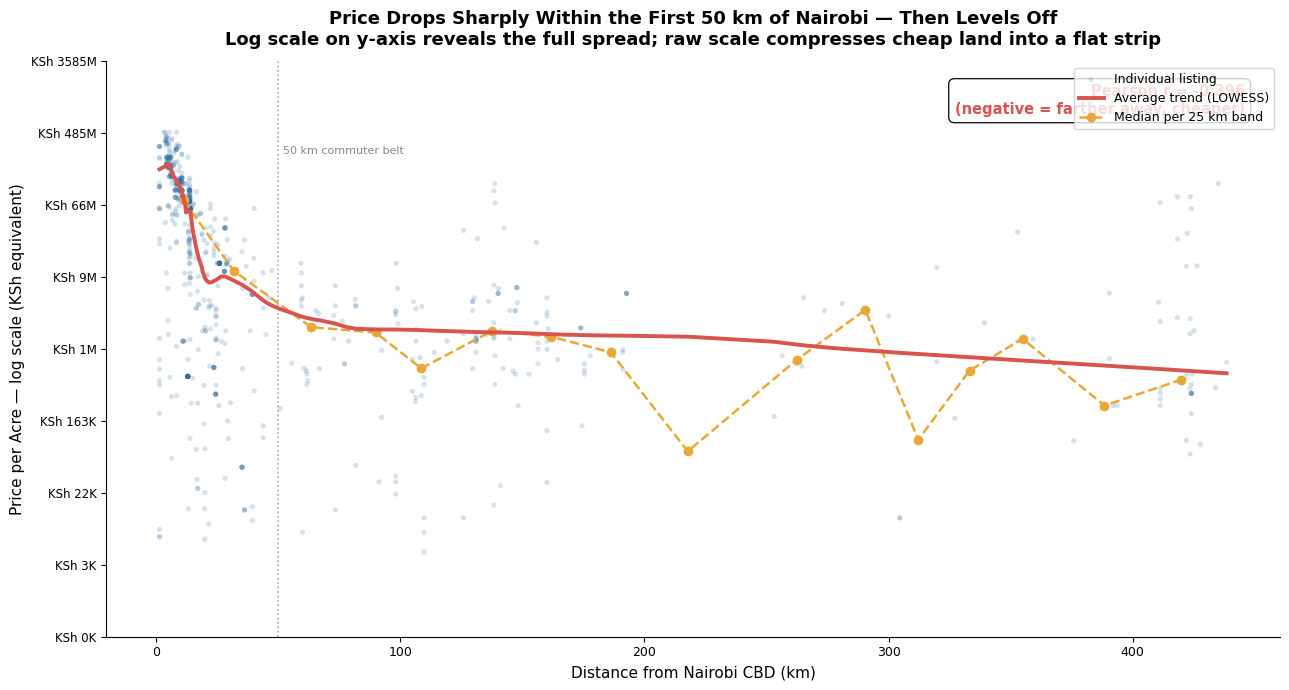

Pearson r: -0.396


In [6]:
plot_df = df[df["dist_to_nairobi_km"].notna() &
             (df["dist_to_nairobi_km"] <= df["dist_to_nairobi_km"].quantile(0.98))].copy()

fig, ax = plt.subplots(figsize=(13, 7))

# Scatter — semi-transparent so density is visible
ax.scatter(plot_df["dist_to_nairobi_km"], plot_df["log_price_per_acre"],
           alpha=0.20, s=14, color=BLUE, edgecolors="none",
           label="Individual listing", zorder=2)

# LOWESS curve — flexible, no linearity assumption
sorted_df = plot_df.sort_values("dist_to_nairobi_km")
sm = lowess(sorted_df["log_price_per_acre"], sorted_df["dist_to_nairobi_km"], frac=0.25)
ax.plot(sm[:, 0], sm[:, 1], color=RED, linewidth=2.8,
        label="Average trend (LOWESS)", zorder=4)

# Binned medians every 25 km
plot_df["band"] = pd.cut(plot_df["dist_to_nairobi_km"],
                         bins=range(0, int(plot_df["dist_to_nairobi_km"].quantile(0.97))+25, 25))
bm = plot_df.groupby("band", observed=True)["log_price_per_acre"].median()
bx = plot_df.groupby("band", observed=True)["dist_to_nairobi_km"].mean()
ax.plot(bx.values, bm.values, color=ORANGE, linewidth=1.8,
        linestyle="--", marker="o", markersize=6,
        label="Median per 25 km band", zorder=3)

# Commuter belt reference line
ax.axvline(50, color=GREY, linewidth=1.2, linestyle=":", alpha=0.7)
ax.text(52, plot_df["log_price_per_acre"].quantile(0.97),
        "50 km commuter belt", fontsize=8, color=GREY, va="top")

# Pearson r annotation
r = plot_df["dist_to_nairobi_km"].corr(plot_df["log_price_per_acre"])
ax.text(0.97, 0.96, f"Pearson r = {r:.3f}\n(negative = farther away, cheaper)",
        transform=ax.transAxes, ha="right", va="top", fontsize=10.5,
        fontweight="bold", color=RED,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.90))

# Y-axis: log price labelled as KSh equivalents
yticks = ax.get_yticks()
ax.set_yticks(yticks)
ax.set_yticklabels(
    [f"KSh {np.exp(y)/1e6:.0f}M" if np.exp(y)>=1e6
     else f"KSh {np.exp(y)/1e3:.0f}K" for y in yticks],
    fontsize=8.5
)

ax.set_title(
    "Price Drops Sharply Within the First 50 km of Nairobi — Then Levels Off\n"
    "Log scale on y-axis reveals the full spread; raw scale compresses cheap land into a flat strip",
    fontsize=13, fontweight="bold"
)
ax.set_xlabel("Distance from Nairobi CBD (km)", fontsize=11)
ax.set_ylabel("Price per Acre — log scale (KSh equivalent)", fontsize=11)
ax.legend(fontsize=9, loc="upper right")

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/chart3a_nairobi_distance.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Pearson r: {r:.3f}")


<a id="cell-4-2"></a>

### Cell 4.2 — Local Reference City Proximity Also Drives Price, Especially Outside Nairobi's Reach

**Question:** Beyond Nairobi's gravitational pull, does proximity to the nearest
local reference city independently explain price variation across Kenya?

**Best practice applied:**
- Same visual structure as Cell 4.1 for direct comparability
- Dots coloured by reference type (blue = Nairobi reference, orange = county town reference)
- Log y-axis used for the same reason as Cell 4.1

**How to interpret:** Compare the Pearson r here to Cell 4.1. If both are strongly negative,
both distance features add independent information and should remain as separate model inputs.
If one is much weaker, it adds little beyond what the other already captures.


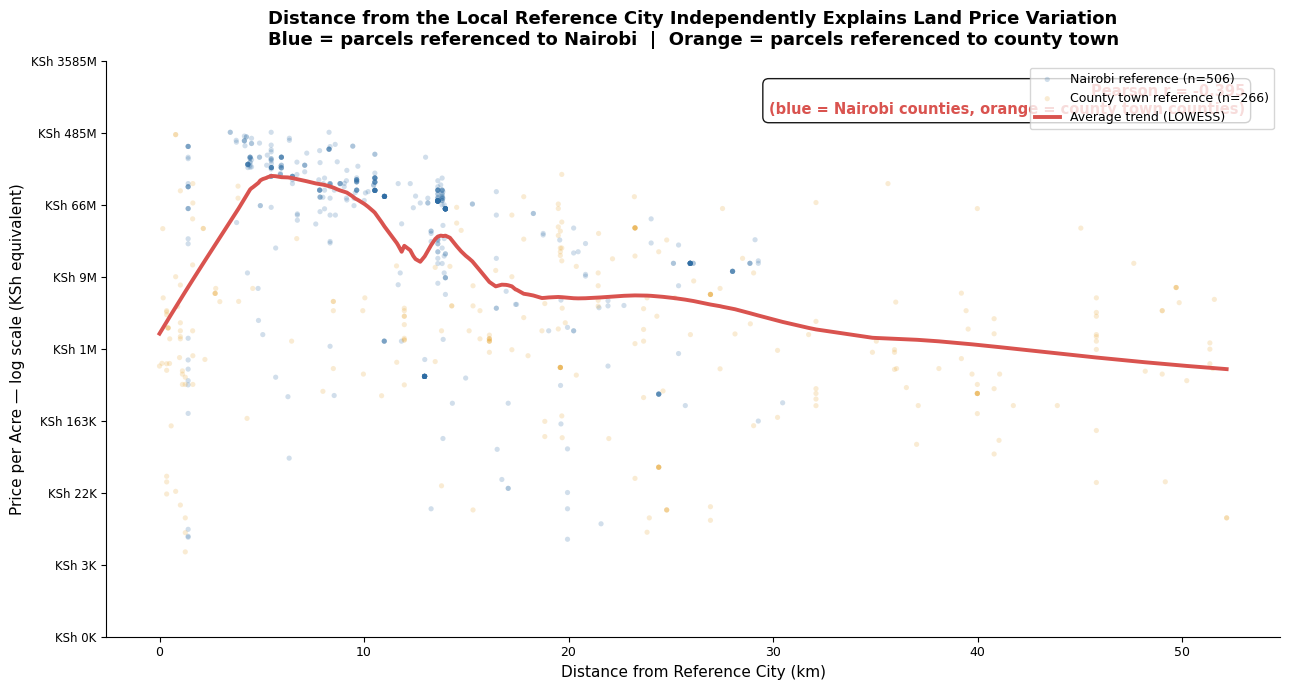

Pearson r: -0.395


In [7]:
plot_df2 = df[df["reference_city_dist_km"].notna() &
              (df["reference_city_dist_km"] <= df["reference_city_dist_km"].quantile(0.97))].copy()

plot_df2["ref_type"] = np.where(
    plot_df2["reference_city"] == "Nairobi", "Nairobi reference", "County town reference"
)

fig, ax = plt.subplots(figsize=(13, 7))

color_map = {"Nairobi reference": BLUE, "County town reference": ORANGE}
for rtype, color in color_map.items():
    sub = plot_df2[plot_df2["ref_type"] == rtype]
    ax.scatter(sub["reference_city_dist_km"], sub["log_price_per_acre"],
               alpha=0.22, s=14, color=color, edgecolors="none",
               label=f"{rtype} (n={len(sub):,})", zorder=2)

# LOWESS on full dataset
ss  = plot_df2.sort_values("reference_city_dist_km")
sm2 = lowess(ss["log_price_per_acre"], ss["reference_city_dist_km"], frac=0.3)
ax.plot(sm2[:, 0], sm2[:, 1], color=RED, linewidth=2.8,
        label="Average trend (LOWESS)", zorder=4)

r2 = plot_df2["reference_city_dist_km"].corr(plot_df2["log_price_per_acre"])
ax.text(0.97, 0.96,
        f"Pearson r = {r2:.3f}\n(blue = Nairobi counties, orange = county town counties)",
        transform=ax.transAxes, ha="right", va="top", fontsize=10.5,
        fontweight="bold", color=RED,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.90))

yticks = ax.get_yticks()
ax.set_yticks(yticks)
ax.set_yticklabels(
    [f"KSh {np.exp(y)/1e6:.0f}M" if np.exp(y)>=1e6
     else f"KSh {np.exp(y)/1e3:.0f}K" for y in yticks], fontsize=8.5
)

ax.set_title(
    "Distance from the Local Reference City Independently Explains Land Price Variation\n"
    "Blue = parcels referenced to Nairobi  |  Orange = parcels referenced to county town",
    fontsize=13, fontweight="bold"
)
ax.set_xlabel("Distance from Reference City (km)", fontsize=11)
ax.set_ylabel("Price per Acre — log scale (KSh equivalent)", fontsize=11)
ax.legend(fontsize=9, loc="upper right")

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/chart3b_town_distance.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Pearson r: {r2:.3f}")


<a id="cell-4-3"></a>

### Cell 4.3 — County-Town Distance vs Price per Acre

**Question:** Does distance from the county town matter for price, once the Nairobi and reference-city effects are already visible in Cells 4.1 and 4.2?

**How to read:** Same visual structure as Cell 4.1 — a semi-transparent scatter of listings, a LOWESS trend curve and medians per 25 km band — so the three distance charts can be compared directly. The annotation reports the Spearman rank correlation ρ (Cell 4.1 shows Pearson r; the rank correlation is robust to outliers and to monotone but non-linear trends). A flat LOWESS curve with ρ near zero would mean the county-town distance adds little beyond what the other two distance features already capture.


In [ ]:
# County-town distance vs log price — same visual structure as Cell 4.1
plot_df3 = df[df["dist_to_county_town_km"].notna() &
              (df["dist_to_county_town_km"] <= df["dist_to_county_town_km"].quantile(0.98))].copy()

fig, ax = plt.subplots(figsize=(13, 7))

# Scatter — semi-transparent so density is visible
ax.scatter(plot_df3["dist_to_county_town_km"], plot_df3["log_price_per_acre"],
           alpha=0.20, s=14, color=BLUE, edgecolors="none",
           label="Individual listing", zorder=2)

# LOWESS curve — flexible, no linearity assumption
sorted_df3 = plot_df3.sort_values("dist_to_county_town_km")
sm3 = lowess(sorted_df3["log_price_per_acre"], sorted_df3["dist_to_county_town_km"], frac=0.25)
ax.plot(sm3[:, 0], sm3[:, 1], color=RED, linewidth=2.8,
        label="Average trend (LOWESS)", zorder=4)

# Binned medians every 25 km
plot_df3["band"] = pd.cut(plot_df3["dist_to_county_town_km"],
                          bins=range(0, int(plot_df3["dist_to_county_town_km"].quantile(0.97))+25, 25))
bm3 = plot_df3.groupby("band", observed=True)["log_price_per_acre"].median()
bx3 = plot_df3.groupby("band", observed=True)["dist_to_county_town_km"].mean()
ax.plot(bx3.values, bm3.values, color=ORANGE, linewidth=1.8,
        linestyle="--", marker="o", markersize=6,
        label="Median per 25 km band", zorder=3)

# Spearman rho annotation (Cell 4.1 shows Pearson r; rho is rank-based)
rho3 = stats.spearmanr(plot_df3["dist_to_county_town_km"], plot_df3["log_price_per_acre"])
ax.text(0.97, 0.96, f"Spearman \u03c1 = {rho3.statistic:.3f}\n(rank correlation; negative = farther away, cheaper)",
        transform=ax.transAxes, ha="right", va="top", fontsize=10.5,
        fontweight="bold", color=RED,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.90))

# Y-axis: log price labelled as KSh equivalents
yticks = ax.get_yticks()
ax.set_yticks(yticks)
ax.set_yticklabels(
    [f"KSh {np.exp(y)/1e6:.0f}M" if np.exp(y) >= 1e6
     else f"KSh {np.exp(y)/1e3:.0f}K" for y in yticks],
    fontsize=8.5
)

ax.set_title(
    f"County-Town Distance vs Price per Acre — Spearman \u03c1 = {rho3.statistic:.3f} "
    f"(n={len(plot_df3):,})\n"
    "Same structure as Cell 4.1 (scatter, LOWESS trend, medians per 25 km band) for direct comparison",
    fontsize=13, fontweight="bold"
)
ax.set_xlabel("Distance from County Town (km)", fontsize=11)
ax.set_ylabel("Price per Acre — log scale (KSh equivalent)", fontsize=11)
ax.legend(fontsize=9, loc="upper right")

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/chart14_county_town_distance.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Spearman rho (county-town distance vs log price): {rho3.statistic:.3f} "
      f"(p = {rho3.pvalue:.2e}, n = {len(plot_df3):,})")


<a id="cell-4-4"></a>

### Cell 4.4 — Water-Body Distance Flag vs Price per Acre

**Question:** Do listings that have a measured water-body distance (counties bordering a water body) differ in price from the rest?

**How to read:** Boxplots of log price per acre for the two groups, with the n per group on the x labels and jittered raw listings behind the boxes; the y axis is labelled in KSh. The Mann-Whitney U test (annotated and printed) says whether the two price distributions differ beyond chance. Note that the "water distance measured" group is very small — the distance exists only for counties that border a water body — so the comparison is indicative rather than conclusive.


In [ ]:
# Water-body distance flag — does having a measured distance go with different prices?
# dist_to_water_body_km is null by design for ~96% of listings (counties that do
# not border a water body), so the raw distance is replaced by this 0/1 flag.
df["has_water_body_distance"] = df["dist_to_water_body_km"].notna().astype(int)

group_no  = df.loc[df["has_water_body_distance"] == 0, "log_price_per_acre"]
group_yes = df.loc[df["has_water_body_distance"] == 1, "log_price_per_acre"]
n_no, n_yes = len(group_no), len(group_yes)
med_no  = float(np.exp(group_no.median()))
med_yes = float(np.exp(group_yes.median()))

u_stat, p_val = stats.mannwhitneyu(group_no, group_yes, alternative="two-sided")

fig, ax = plt.subplots(figsize=(13, 7))
box = ax.boxplot([group_no.values, group_yes.values], patch_artist=True, widths=0.45)
for patch, col in zip(box["boxes"], [BLUE, ORANGE]):
    patch.set_facecolor(col)
    patch.set_alpha(0.65)
for med in box["medians"]:
    med.set_color(DARK)
    med.set_linewidth(2.2)

# Jittered raw listings behind the boxes
rng_wb = np.random.default_rng(SEED)
for i, g in enumerate([group_no, group_yes], start=1):
    ax.scatter(rng_wb.normal(i, 0.05, size=len(g)), g.values,
               s=10, color=DARK, alpha=0.25, zorder=3, linewidths=0)

ax.set_xticks([1, 2])
ax.set_xticklabels([f"No water distance measured\n(n={n_no:,})",
                    f"Water distance measured\n(n={n_yes:,})"], fontsize=10.5)

# Y-axis: log price labelled as KSh equivalents
yticks = ax.get_yticks()
ax.set_yticks(yticks)
ax.set_yticklabels(
    [f"KSh {np.exp(y)/1e6:.0f}M" if np.exp(y) >= 1e6
     else f"KSh {np.exp(y)/1e3:.0f}K" for y in yticks],
    fontsize=8.5
)

p_str = "p < 0.001" if p_val < 0.001 else f"p = {p_val:.3f}"
ax.text(0.97, 0.96, f"Mann-Whitney U = {u_stat:,.0f}\n{p_str}",
        transform=ax.transAxes, ha="right", va="top", fontsize=10.5,
        fontweight="bold", color=RED,
        bbox=dict(boxstyle="round,pad=0.4", facecolor="white", alpha=0.90))
ax.text(0.03, 0.96,
        f"Note: the 'water distance measured' group is small\n"
        f"(n={n_yes:,} of {n_no + n_yes:,} listings, {100 * n_yes / (n_no + n_yes):.1f}%) —\n"
        "the distance exists only for counties that border\na water body, so treat the comparison as indicative.",
        transform=ax.transAxes, ha="left", va="top", fontsize=9, color=GREY,
        bbox=dict(boxstyle="round,pad=0.35", facecolor=LIGHT,
                  alpha=0.90, edgecolor="#cccccc"))

ax.set_title(
    f"Price per Acre With and Without a Measured Water-Body Distance\n"
    f"Medians: {fmt_ksh(med_no)} vs {fmt_ksh(med_yes)} per acre  |  Mann-Whitney {p_str}",
    fontsize=13, fontweight="bold"
)
ax.set_xlabel("Water-body distance flag (has_water_body_distance)", fontsize=11)
ax.set_ylabel("Price per Acre — log scale (KSh equivalent)", fontsize=11)

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/chart15_water_body_indicator.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: chart15_water_body_indicator.png")
print(f"Group medians: no water distance {fmt_ksh(med_no)} (n={n_no:,}) | "
      f"water distance {fmt_ksh(med_yes)} (n={n_yes:,})")
print(f"Mann-Whitney U = {u_stat:,.0f}, {p_str}")


<a id="phase-5"></a>

## Phase 5 — Service Scores

This phase examines the three service scores: their distributions, their relationship with price, their mutual correlation, and their variation across the largest counties.

<a id="cell-5-0"></a>

### Cell 5.0 — Score Distribution Histograms (Shared Helper)

The next three cells (5.1–5.3) share a reusable helper function `score_histogram()` that is defined below.
Each chart answers: **how is this composite score distributed across all listings?**


In [ ]:
from scipy.stats import gaussian_kde

def score_histogram(score_col, score_label, color, filename, title,
                    geo_col=None, geo_label=None, geo_color=DARK):
    """Plot a histogram + KDE overlay for a score column, with mean/median lines
    and a summary statistics annotation box."""
    raw = df[score_col].dropna()
    # If >50 % of values are exactly zero, show only the non-zero tail and add a note
    if (raw == 0).mean() > 0.5:
        sub = raw[raw > 0]
    else:
        sub = raw

    fig, ax = plt.subplots(figsize=(13, 7))

    counts, bin_edges, _ = ax.hist(
        sub, bins=30, color=color, alpha=0.72,
        edgecolor="white", linewidth=0.6, zorder=2,
        label=(f"{score_label} (text-boosted)" if geo_col is not None else None),
    )

    # Geographic-only overlay (round-3 EDA update): a second hatched
    # histogram of geo_col on the SAME bins, no fill so the existing
    # series stays visible. Aligned to the same rows as `sub` so the
    # comparison is fair on a zero-inflated column.
    if geo_col is not None:
        raw_geo = df[geo_col].dropna()
        sub_geo = raw_geo.reindex(sub.index).dropna()
        ax.hist(
            sub_geo, bins=bin_edges, facecolor="none", edgecolor=geo_color,
            hatch="///", linewidth=1.0, alpha=0.85,
            label=geo_label or f"{score_label} (geographic-only)", zorder=3,
        )

    # KDE overlay — smoothed density curve scaled to count axis
    kde_x = np.linspace(sub.min(), sub.max(), 300)
    kde   = gaussian_kde(sub, bw_method="scott")
    kde_y = kde(kde_x) * len(sub) * (bin_edges[1] - bin_edges[0])
    ax.plot(kde_x, kde_y, color=DARK, linewidth=2.2,
            label="KDE (smoothed density)", zorder=4)

    # Mean and median reference lines
    mean_val   = sub.mean()
    median_val = sub.median()
    ax.axvline(mean_val,   color=RED,    linewidth=1.8, linestyle="--",
               label=f"Mean = {mean_val:.1f}", zorder=5)
    ax.axvline(median_val, color=ORANGE, linewidth=1.8, linestyle=":",
               label=f"Median = {median_val:.1f}", zorder=5)

    # Summary statistics annotation
    q25, q75 = sub.quantile(0.25), sub.quantile(0.75)
    stats_text = (
        f"n = {len(sub):,}\n"
        f"Mean   = {mean_val:.1f}\n"
        f"Median = {median_val:.1f}\n"
        f"Std    = {sub.std():.1f}\n"
        f"IQR    = [{q25:.1f}, {q75:.1f}]"
    )
    ax.text(0.97, 0.96, stats_text,
            transform=ax.transAxes, ha="right", va="top",
            fontsize=10, fontfamily="monospace", color=DARK,
            bbox=dict(boxstyle="round,pad=0.45", facecolor="white",
                      alpha=0.92, edgecolor="#cccccc"))

    # Zero-inflation notice
    n_zeros   = (raw == 0).sum()
    pct_zeros = n_zeros / len(raw) * 100
    if pct_zeros > 10:
        ax.text(0.03, 0.96,
                f"Note: {n_zeros:,} listings ({pct_zeros:.0f}%) score exactly 0\n"
                f"(description silent — not necessarily absent)",
                transform=ax.transAxes, ha="left", va="top",
                fontsize=9, color=GREY,
                bbox=dict(boxstyle="round,pad=0.35", facecolor=LIGHT,
                          alpha=0.90, edgecolor="#cccccc"))

    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel(f"{score_label} (0 = poorest access  |  100 = best access)", fontsize=11)
    ax.set_ylabel("Number of Listings", fontsize=11)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f"{int(x):,}"))
    ax.legend(fontsize=9)

    plt.tight_layout()
    plt.savefig(f"{OUTPUTS}/{filename}", dpi=150, bbox_inches="tight")
    plt.show()
    print(f"Saved: {filename}  |  n={len(sub):,}  mean={mean_val:.2f}  "
          f"median={median_val:.2f}  std={sub.std():.2f}")

print("score_histogram() helper defined.")


<a id="cell-5-1"></a>

### Cell 5.1 — Distribution of Amenities Scores Across All Listings

**Question:** How are amenities scores distributed across the dataset — are most
listings clustered at the low end (poor service access), or is the distribution
broadly spread, indicating genuine variation in the feature?

**How to interpret:** A distribution piled up at 0 means most listings have poor or
unscored amenity access. A roughly bell-shaped distribution means the score captures
real variation. A bimodal shape may indicate two distinct listing populations (urban vs rural).


In [ ]:
score_histogram(
    "amenities_score", "Amenities Score", BLUE,
    "chart4a_amenities_score.png",
    "Distribution of Amenities Scores — Text-Boosted (solid) vs Geographic-Only (hatched)\n"
    "Amenities score = proximity to hospitals, schools, markets, banks (Phase 5 pipeline); "
    "hatched = OSM distances only, no description boost",
    geo_col="amenities_score_osm",
    geo_label="Amenities Score (geographic-only, no description boost)",
    geo_color=DARK,
)


<a id="cell-5-2"></a>

### Cell 5.2 — Distribution of Accessibility Scores Across All Listings

**Question:** How are accessibility scores distributed — does road access vary widely
across listings, or do most cluster at similar levels?

**How to interpret:** Compare the shape here to Cell 5.1 (amenities). If accessibility
scores are more uniformly spread than amenities scores, road access is a more
discriminating feature. A strong right-skew would mean most land has poor
road access, with a small premium tier of well-connected parcels.


In [ ]:
score_histogram(
    "accessibility_score", "Accessibility Score", ORANGE,
    "chart4b_accessibility_score.png",
    "Distribution of Accessibility Scores — Text-Boosted (solid) vs Geographic-Only (hatched)\n"
    "Accessibility score = road quality (50%) + town decay (30%) + Nairobi decay (20%); "
    "hatched = OSM distances only, no description boost",
    geo_col="accessibility_score_osm",
    geo_label="Accessibility Score (geographic-only, no description boost)",
    geo_color=DARK,
)


<a id="cell-5-3"></a>

### Cell 5.3 — Distribution of Infrastructure Scores Across All Listings

**Question:** How are infrastructure scores distributed — and what share of listings
describe on-site infrastructure (borehole, electricity, fencing) vs those that are silent?

**Important context:** The infrastructure score is extracted from free-text listing
descriptions via NLP regex. A score of 0 means the description did not mention
infrastructure — not that the land has none.

**How to interpret:** Focus on the non-zero bars. If they are uniformly spread from
20 to 100, the extraction captured a genuine range of infrastructure quality. If
the non-zero bars cluster tightly around a single value, the score may have limited
discriminating power and a binary flag might be more informative.


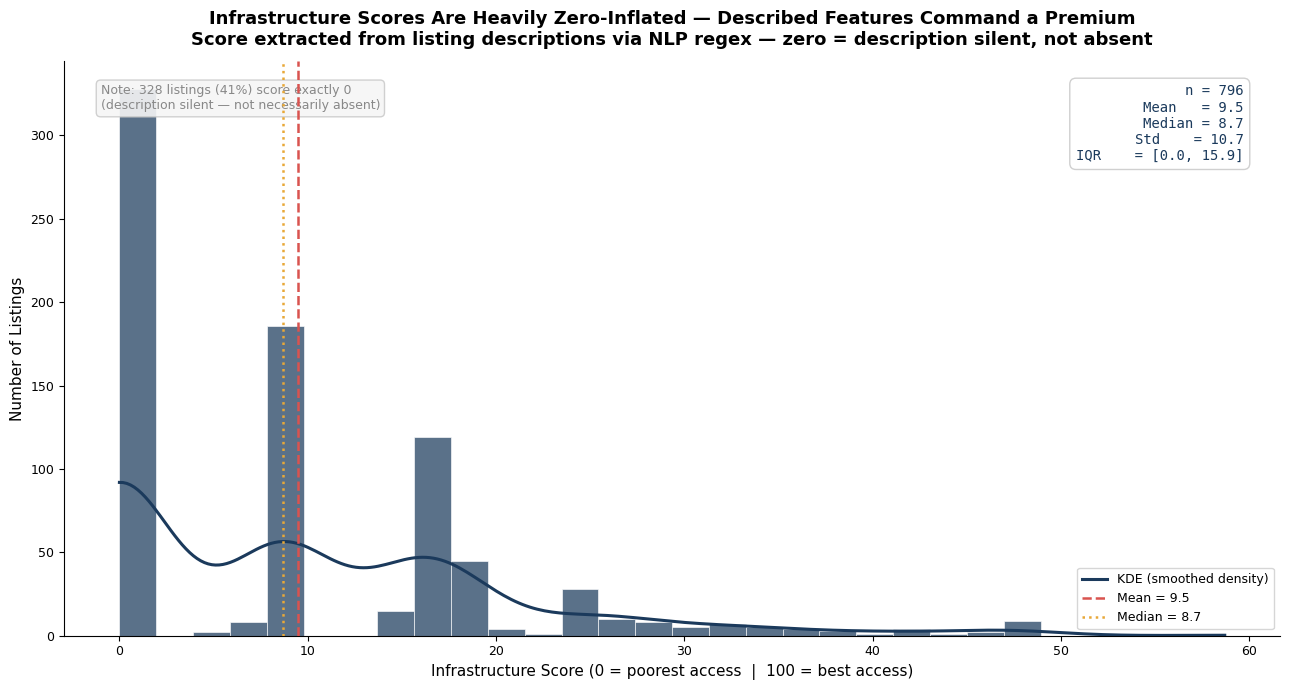

Saved: chart4c_infrastructure_score.png  |  n=796  mean=9.50  median=8.70  std=10.66


In [11]:
score_histogram(
    "infrastructure_score", "Infrastructure Score", DARK,
    "chart4c_infrastructure_score.png",
    "Infrastructure Scores Are Heavily Zero-Inflated — Described Features Command a Premium\n"
    "Score extracted from listing descriptions via NLP regex — zero = description silent, not absent"
)


<a id="cell-5-4"></a>

### Cell 5.4 — Median Price by Score Quintile

**Question:** Do listings with higher service scores also have higher prices, for each of the three scores?

**How to read:** Each line is one score: listings are split into quintile bands of that score (bands whose edges collapse to duplicates — e.g. the zero-inflated infrastructure score — are dropped, so a line may have fewer than five points), and the line tracks the median price per acre per band. Rising lines mean higher scores go with higher prices. The number of bands and the n per band are in the legend, the exact medians are printed under the chart, and quintile bands are within-score comparisons — Q3 of amenities is not the same set of listings as Q3 of infrastructure.


In [ ]:
# Median log price by score quintile — one line per service score
score_specs = [
    ("amenities_score_osm",      "Amenities",      BLUE),
    ("accessibility_score_osm",  "Accessibility",  ORANGE),
    ("infrastructure_score",     "Infrastructure", DARK),
]

fig, ax = plt.subplots(figsize=(13, 7))
quintile_rows = []
gap_ksh = {}

for col, label, color in score_specs:
    sub = df[["log_price_per_acre", col]].dropna(subset=[col])
    # Quintile bands of the score; duplicate edges (zero-inflated scores) are dropped
    bands = pd.qcut(sub[col], 5, labels=False, duplicates="drop")
    med   = sub.groupby(bands)["log_price_per_acre"].median()
    ns    = sub.groupby(bands).size()
    x     = (med.index + 1).values
    ax.plot(x, med.values, color=color, linewidth=2.4, marker="o", markersize=7,
            label=f"{label} ({len(med)} bands, n per band {ns.min():,}\u2013{ns.max():,})",
            zorder=3)
    gap_ksh[label] = float(np.exp(med.iloc[-1]) - np.exp(med.iloc[0]))
    for band, m, n in zip(med.index, med.values, ns.values):
        quintile_rows.append((label, int(band) + 1, int(n), float(np.exp(m))))

steepest = max(gap_ksh, key=gap_ksh.get)
ax.set_xticks(range(1, 6))
ax.set_xticklabels([f"Q{i}" for i in range(1, 6)], fontsize=10)

# Y-axis: log price labelled as KSh equivalents
yticks = ax.get_yticks()
ax.set_yticks(yticks)
ax.set_yticklabels(
    [f"KSh {np.exp(y)/1e6:.0f}M" if np.exp(y) >= 1e6
     else f"KSh {np.exp(y)/1e3:.0f}K" for y in yticks],
    fontsize=8.5
)

ax.set_title(
    f"Median Price per Acre by Score Quintile — {steepest} Shows the Largest "
    f"Gap Between Lowest and Highest Band\n"
    f"Gap for {steepest}: {fmt_ksh(gap_ksh[steepest])} per acre between band 1 and the "
    f"highest band; quintiles are within-score comparisons; "
    f"service scores are the geographic-only (_osm) variants — no description boosts",
    fontsize=13, fontweight="bold"
)
ax.set_xlabel("Score band (Q1 = lowest-scoring 20% of listings, Q5 = highest)", fontsize=11)
ax.set_ylabel("Median Price per Acre (KSh equivalent)", fontsize=11)
ax.legend(fontsize=9.5, loc="best")
ax.grid(axis="y", alpha=0.25, zorder=1)

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/chart16_price_by_score_band.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: chart16_price_by_score_band.png")
print(pd.DataFrame(quintile_rows,
                   columns=["score", "band", "n", "median_ppa"])
      .assign(median_ppa=lambda d: d["median_ppa"].map(fmt_ksh))
      .to_string(index=False))


<a id="cell-5-5"></a>

### Cell 5.5 — Spearman Correlations Between Service Scores

**Question:** How strongly are the amenities, accessibility and infrastructure scores related to each other?

**How to read:** Lower-triangle Spearman correlations between the three scores on the EDA sample, pairwise-complete — the number of rows behind each pair and the number of complete rows are printed under the chart. High positive values mean the scores partly measure the same thing (they share geospatial inputs); values near zero mean they are complementary. Whether any redundancy matters for a model is decided in Notebook 3.


In [ ]:
# Spearman correlations between the three service scores (pairwise-complete)
score_cols   = ["amenities_score_osm", "accessibility_score_osm", "infrastructure_score"]
score_labels = ["Amenities", "Accessibility", "Infrastructure"]

score_df_c  = df[score_cols]
rho_scores  = score_df_c.corr(method="spearman").round(3)
rho_scores.index   = score_labels
rho_scores.columns = score_labels

n_scores = score_df_c.notna().astype(int)
n_mat_s  = (n_scores.T @ n_scores)                     # rows behind each pair
n_mat_s.index, n_mat_s.columns = score_labels, score_labels
n_complete = int(n_scores.all(axis=1).sum())

fig, ax = plt.subplots(figsize=(8.5, 7))
mask_s = np.triu(np.ones_like(rho_scores, dtype=bool), k=1)
sns.heatmap(
    rho_scores, ax=ax, mask=mask_s,
    annot=True, fmt=".2f",
    cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    linewidths=0.6, linecolor="#eeeeee",
    annot_kws={"size": 12},
    cbar_kws={"shrink": 0.60, "label": "Spearman \u03c1"}
)

ax.set_title(
    f"Spearman Correlations Between the Three Service Scores (geographic-only _osm variants)\n"
    f"Pairwise-complete: n={n_complete:,} rows have all three scores; n per pair printed below; "
    f"amenities and accessibility use the geographic-only scores (no description boosts)",
    fontsize=12.5, fontweight="bold"
)
ax.tick_params(axis="x", rotation=0, labelsize=10)
ax.tick_params(axis="y", rotation=0, labelsize=10)

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/chart17_score_correlation.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: chart17_score_correlation.png")
print(rho_scores.to_string())
print(f"\nRows behind each pair:")
print(n_mat_s.to_string())
print(f"\nComplete rows (all three scores): {n_complete:,} of {len(df):,}")


<a id="cell-5-6"></a>

### Cell 5.6 — Service Scores by County

**Question:** How do the three service scores vary across the largest counties?

**How to read:** Grouped boxplots — three boxes (one per score, same colours as Cells 5.1–5.3) for each of the `TOP_COUNTIES` largest counties by listing count, with the county's n in the x label. Boxes show the interquartile range and the median (outliers hidden for readability). Compare within a county — which score is strongest there? — and across counties — which counties are best served? A county can score high on one dimension and low on another.


In [ ]:
# Service scores by county — grouped boxplots for the largest counties
top_counties = df["county"].value_counts().head(TOP_COUNTIES).index
sub = df[df["county"].isin(top_counties)]

box_data, box_pos, box_colors = [], [], []
group_centers, group_labels = [], []
pos = 1.0
for county in top_counties:
    start = pos
    for col, _label, color in score_specs:
        vals = sub.loc[sub["county"] == county, col].dropna().values
        box_data.append(vals if len(vals) else np.array([np.nan]))
        box_pos.append(pos)
        box_colors.append(color)
        pos += 1.0
    group_centers.append((start + pos - 1.0) / 2.0)
    group_labels.append(f"{county}\n(n={int((sub['county'] == county).sum()):,})")
    pos += 0.9                                     # gap between county groups

fig, ax = plt.subplots(figsize=(14, 7))
bp = ax.boxplot(box_data, positions=box_pos, patch_artist=True, widths=0.72,
                showfliers=False)
for patch, color in zip(bp["boxes"], box_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.65)
for med in bp["medians"]:
    med.set_color(DARK)
    med.set_linewidth(1.8)

ax.set_xticks(group_centers)
ax.set_xticklabels(group_labels, fontsize=9.5)

handles = [mpatches.Patch(facecolor=color, edgecolor="#888888", linewidth=0.5, label=label)
           for _col, label, color in score_specs]
ax.legend(handles=handles, title="Score", fontsize=9, title_fontsize=9.5,
          loc="lower left", framealpha=0.92)

med_amen    = sub.groupby("county")["amenities_score_osm"].median()
best_county = med_amen.idxmax()

ax.set_title(
    f"Service Scores by County — {best_county} Has the Highest Median Amenities Score "
    f"Among the {TOP_COUNTIES} Largest Counties\n"
    f"Box = interquartile range, line = median, outliers hidden; n per county in the x labels; "
    f"counties ranked by listing count; service scores are the geographic-only (_osm) variants",
    fontsize=13, fontweight="bold"
)
ax.set_xlabel("County (largest by listing count)", fontsize=11)
ax.set_ylabel("Score (0 = poorest access  |  100 = best)", fontsize=11)
ax.set_ylim(-2, 104)

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/chart18_scores_by_county.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: chart18_scores_by_county.png")
print((sub.groupby("county")[["amenities_score_osm", "accessibility_score_osm",
                              "infrastructure_score"]]
       .median().round(1).sort_values("amenities_score_osm", ascending=False).to_string()))


<a id="cell-5-7"></a>

### Cell 5.7 — Geographic-Only vs Text-Boosted Scores

**Question:** How different are the geographic-only scores (the ones the model and the app use) from the text-boosted scores (the training-data variants that include description-keyword floors)?

**How to read:** One scatter, two series — amenities (blue) and accessibility (orange). For each, x = text-boosted score, y = geographic-only score. The dashed line is y = x — points on it received no description boost; points above it received a positive boost (the boosted value is larger). The title reports the computed share of listings whose two scores differ by more than 5 points, for each score.


In [ ]:
# Cell 5.7 — Geographic-only vs text-boosted scores: one scatter, two
# series (amenities and accessibility) with a y = x diagonal. The title
# reports the computed share of listings whose two scores differ by more
# than 5 points (per score).
amen_pair = df[["amenities_score", "amenities_score_osm"]].dropna()
acc_pair  = df[["accessibility_score", "accessibility_score_osm"]].dropna()

amen_diff_5 = float((
    (amen_pair["amenities_score"] - amen_pair["amenities_score_osm"])
    .abs() > 5
).mean() * 100)
acc_diff_5  = float((
    (acc_pair["accessibility_score"] - acc_pair["accessibility_score_osm"])
    .abs() > 5
).mean() * 100)

fig, ax = plt.subplots(figsize=(10, 10))
ax.scatter(
    amen_pair["amenities_score"], amen_pair["amenities_score_osm"],
    s=24, alpha=0.55, color=BLUE, edgecolors="white", linewidths=0.3,
    label=f"Amenities (n={len(amen_pair):,})", zorder=2,
)
ax.scatter(
    acc_pair["accessibility_score"], acc_pair["accessibility_score_osm"],
    s=24, alpha=0.55, color=ORANGE, edgecolors="white", linewidths=0.3,
    label=f"Accessibility (n={len(acc_pair):,})", zorder=2,
)
# Diagonal y = x — the no-boost reference
ax.plot([0, 100], [0, 100], color=DARK, linewidth=1.5, linestyle="--",
        label="y = x (no description boost)", zorder=3)

ax.set_title(
    f"Geographic-Only vs Text-Boosted Service Scores — Description "
    f"Boosts Move {amen_diff_5:.1f}% of Amenities and {acc_diff_5:.1f}% "
    f"of Accessibility Listings by More Than 5 Points\n"
    f"x = text-boosted (description keywords applied, training data); "
    f"y = geographic-only (OSM distances only); points above the diagonal "
    f"received a positive boost",
    fontsize=12.5, fontweight="bold",
)
ax.set_xlabel("Text-boosted score (description keywords applied, training data)",
             fontsize=11)
ax.set_ylabel("Geographic-only score (OSM distances, no description boost)",
             fontsize=11)
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_aspect("equal", adjustable="box")
ax.legend(fontsize=10, loc="lower right")
ax.grid(alpha=0.20, zorder=1)

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/chart23_scores_boosted_vs_geographic.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: chart23_scores_boosted_vs_geographic.png")
print(f"  amenities     : n={len(amen_pair):,} | "
      f"share |boost - geo| > 5: {amen_diff_5:.1f}%")
print(f"  accessibility : n={len(acc_pair):,} | "
      f"share |boost - geo| > 5: {acc_diff_5:.1f}%")


<a id="cell-5-8"></a>

### Cell 5.8 — Parcel Features Mentioned in Listings

**Question:** How often is each parcel-level infrastructure feature (borehole, piped water, fencing, structures, internal road, etc.) mentioned in the listing description — and how often was the infrastructure_score imputed from the county median because the description was silent?

**How to read:** One bar per `infra_<item>` presence column (0/1, set by Notebook 1 Phase 7 from description keywords), showing the share of listings where it equals 1. The orange bar is the share whose `infra_source == "imputed_county_median"` — the description was too short and the score was filled from the county median (Notebook 1 Cell 7.5). At prediction time these ten presence flags come from the user's parcel checklist, and `infrastructure_score` is recomputed as `sum(weight * item) / max_infra_score * 100`.


In [ ]:
# Cell 5.8 — Parcel features mentioned in listings: bar of the share of
# listings with each infra_<item> == 1, plus the share whose
# infrastructure_score was imputed from the county median (infra_source).
# The ten presence flags are exactly the columns Notebook 1 Phase 7
# wrote next to infrastructure_score; infra_source is set by Cell 7.5.
INFRA_ITEM_LABELS = {
    "borehole":       "Borehole",
    "piped_water":    "Piped water",
    "river_water":     "River / spring water",
    "water_tank":     "Water tank",
    "grid_electric":  "Grid electricity",
    "solar_electric": "Solar electricity",
    "full_fence":     "Fully fenced",
    "partial_fence":  "Partially fenced",
    "structures":     "Structures on site",
    "internal_road": "Internal road",
}

n_total = len(df)
prevalence = []
for item, label in INFRA_ITEM_LABELS.items():
    col = f"infra_{item}"
    if col in df.columns:
        n_one   = int((df[col] == 1).sum())
        share   = 100.0 * n_one / n_total
        prevalence.append((label, share, n_one, col))

# Imputed-from-county-median share (infra_source) — orange bar.
if "infra_source" in df.columns:
    n_imp  = int((df["infra_source"] == "imputed_county_median").sum())
    s_imp  = 100.0 * n_imp / n_total
    prevalence.append(
        ("Imputed from county median (infra_source)", s_imp, n_imp, "infra_source")
    )

# Sort descending by share so the most-prevalent feature is at the top.
prevalence.sort(key=lambda t: -t[1])
labels      = [t[0] for t in prevalence]
shares      = [t[1] for t in prevalence]
counts      = [t[2] for t in prevalence]
bar_colors  = [ORANGE if t[3] == "infra_source" else BLUE for t in prevalence]

fig, ax = plt.subplots(figsize=(13, 7))
bars = ax.barh(np.arange(len(labels)), shares, color=bar_colors,
                height=0.62, zorder=2)
ax.set_yticks(np.arange(len(labels)))
ax.set_yticklabels(labels, fontsize=10)
ax.invert_yaxis()
for bar, n, s in zip(bars, counts, shares):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height() / 2,
            f"{s:.1f}%  (n={n:,})", va="center", fontsize=9, color=DARK)

ax.set_title(
    f"Parcel Features Mentioned in Listings — Share of Listings per "
    f"Item (n={n_total:,}; orange = imputed from county median, blue = "
    f"checklist flag)\n"
    f"infrastructure_score = weighted sum of the ten blue items / "
    f"MAX_INFRA_SCORE * 100 (Notebook 1 Cell 7.4); the orange bar is the "
    f"share whose description was too short to score (Cell 7.5 imputation)",
    fontsize=12.5, fontweight="bold",
)
ax.set_xlabel("Share of listings (%)", fontsize=11)
ax.set_xlim(0, max(shares) * 1.22 if shares else 1)
ax.grid(axis="x", alpha=0.25, zorder=1)

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/chart24_parcel_feature_prevalence.png",
            dpi=150, bbox_inches="tight")
plt.show()
print("Saved: chart24_parcel_feature_prevalence.png")
print(pd.DataFrame({"feature": labels, "share_pct": shares,
                    "n": counts}).round(2).to_string(index=False))


<a id="phase-6"></a>

## Phase 6 — Size and Price Structure

This phase examines parcel size: its distribution, and how price per acre changes with the size of the parcel.

<a id="cell-6-1"></a>

### Cell 6.1 — Larger Parcels Cost More in Total but Less per Acre — The Bulk Discount Effect

**Question:** Does buying more acres give you a better price per acre, and how strong
is this bulk discount in the Kenyan land market?

**Best practice applied:**
- Both axes are log-transformed — raw price and raw size span multiple orders of magnitude
- Trend line slope is annotated — on a log-log plot, slope < 1 means per-acre discount
- Dot colour encodes price per acre (third variable)

**How to interpret:** A trend line slope less than 1.0 confirms a bulk discount. The annotation
interprets this directly in plain language. Outliers far from the band are unusual parcels
worth individual investigation.


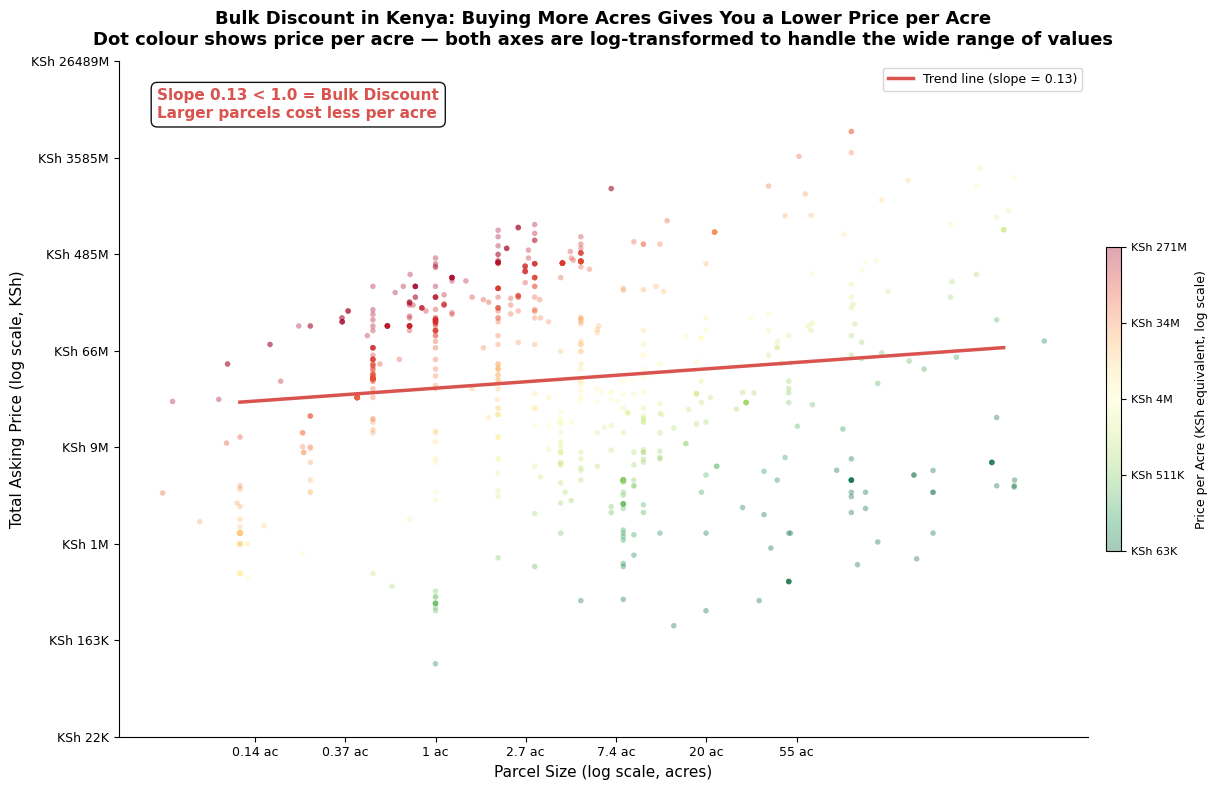

Log-log slope: 0.134
Interpretation: slope < 1 = bulk discount, slope > 1 = size premium


In [14]:
plot_size = df[(df["size_acres"] > 0) &
               df["log_size_acres"].notna() &
               df["log_price_per_acre"].notna()].copy()

plot_size["log_total_price"] = plot_size["log_price_per_acre"] + plot_size["log_size_acres"]

fig, ax = plt.subplots(figsize=(13, 8))

sc = ax.scatter(
    plot_size["log_size_acres"],
    plot_size["log_total_price"],
    c=plot_size["log_price_per_acre"],
    cmap="RdYlGn_r", alpha=0.35, s=16,
    edgecolors="none", zorder=2,
    norm=mcolors.Normalize(
        vmin=plot_size["log_price_per_acre"].quantile(0.05),
        vmax=plot_size["log_price_per_acre"].quantile(0.95)
    )
)

cbar = plt.colorbar(sc, ax=ax, shrink=0.45, pad=0.015)
cbar.set_label("Price per Acre (KSh equivalent, log scale)", fontsize=9, labelpad=6)
lt = np.linspace(plot_size["log_price_per_acre"].quantile(0.05),
                 plot_size["log_price_per_acre"].quantile(0.95), 5)
cbar.set_ticks(lt)
cbar.set_ticklabels(
    [f"KSh {np.exp(v)/1e6:.0f}M" if np.exp(v)>=1e6
     else f"KSh {np.exp(v)/1e3:.0f}K" for v in lt], fontsize=8
)

slope, intercept = np.polyfit(plot_size["log_size_acres"],
                               plot_size["log_total_price"], 1)
x_line = np.linspace(plot_size["log_size_acres"].quantile(0.01),
                     plot_size["log_size_acres"].quantile(0.99), 200)
ax.plot(x_line, intercept + slope * x_line, color=RED,
        linewidth=2.5, label=f"Trend line (slope = {slope:.2f})", zorder=4)

if slope < 1:
    interp = f"Slope {slope:.2f} < 1.0 = Bulk Discount\nLarger parcels cost less per acre"
elif slope > 1:
    interp = f"Slope {slope:.2f} > 1.0 = Size Premium\nLarger parcels cost more per acre"
else:
    interp = f"Slope {slope:.2f} ≈ 1.0 = No bulk effect"

ax.text(0.04, 0.96, interp, transform=ax.transAxes, ha="left", va="top",
        fontsize=11, fontweight="bold", color=RED,
        bbox=dict(boxstyle="round,pad=0.40", facecolor="white", alpha=0.92))

xt = [-2, -1, 0, 1, 2, 3, 4]
ax.set_xticks(xt)
ax.set_xticklabels([f"{np.exp(v):.2g} ac" for v in xt], fontsize=9)

yt = ax.get_yticks()
ax.set_yticks(yt)
ax.set_yticklabels(
    [f"KSh {np.exp(y)/1e6:.0f}M" if np.exp(y)>=1e6
     else f"KSh {np.exp(y)/1e3:.0f}K" for y in yt], fontsize=9
)

ax.set_title(
    "Bulk Discount in Kenya: Buying More Acres Gives You a Lower Price per Acre\n"
    "Dot colour shows price per acre — both axes are log-transformed to handle the wide range of values",
    fontsize=13, fontweight="bold"
)
ax.set_xlabel("Parcel Size (log scale, acres)", fontsize=11)
ax.set_ylabel("Total Asking Price (log scale, KSh)", fontsize=11)
ax.legend(fontsize=9)

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/chart7_size_vs_price_loglog.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Log-log slope: {slope:.3f}")
print("Interpretation: slope < 1 = bulk discount, slope > 1 = size premium")


<a id="cell-6-2"></a>

### Cell 6.2 — Parcel Size Distribution

**Question:** How are parcel sizes distributed, and where do most listings sit?

**How to read:** Histogram of log parcel size — the raw scale spans several orders of magnitude, so the log scale is what shows the shape. Vertical lines mark the 10th, 50th and 90th percentiles with their acre values in the legend, the x tick labels convert the log axis back to acres, and the title reports the median and the 10th–90th percentile range computed from the data.


In [ ]:
# Parcel size distribution — log-scale histogram with percentiles
sizes     = df["size_acres"]
log_sizes = df["log_size_acres"]
p10, p50, p90 = sizes.quantile([0.10, 0.50, 0.90])
n_sized = int(sizes.notna().sum())

fig, ax = plt.subplots(figsize=(13, 7))
ax.hist(log_sizes, bins=40, color=BLUE, alpha=0.72,
        edgecolor="white", linewidth=0.6, zorder=2)

ax.axvline(np.log(p10), color=ORANGE, linewidth=1.8, linestyle="--", zorder=4,
           label=f"10th percentile: {p10:.2f} acres")
ax.axvline(np.log(p50), color=RED,    linewidth=2.0, linestyle=":" , zorder=4,
           label=f"Median: {p50:.2f} acres")
ax.axvline(np.log(p90), color=GREEN,  linewidth=1.8, linestyle="--", zorder=4,
           label=f"90th percentile: {p90:.2f} acres")
ax.legend(fontsize=9.5)

# X axis: log sizes labelled in acres
xt = ax.get_xticks()
ax.set_xticks(xt)
ax.set_xticklabels([f"{np.exp(v):.2g} ac" for v in xt], fontsize=9)

ax.set_title(
    f"Parcel Size Distribution — Median {p50:.2f} Acres, 90% of Listings Between "
    f"{p10:.2f} and {p90:.2f} Acres\n"
    f"Log-scale histogram of size_acres (n={n_sized:,} listings); vertical lines mark "
    f"the 10th, 50th and 90th percentiles",
    fontsize=13, fontweight="bold"
)
ax.set_xlabel("Parcel Size (log scale, acres)", fontsize=11)
ax.set_ylabel("Number of Listings", fontsize=11)

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/chart19_size_distribution.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: chart19_size_distribution.png  |  n={n_sized:,} | "
      f"p10={p10:.2f}, median={p50:.2f}, p90={p90:.2f} acres")


<a id="cell-6-3"></a>

### Cell 6.3 — Price per Acre by Size Band

**Question:** How does the price per acre change across parcel-size bands?

**How to read:** Boxplots of price per acre for six bands — under 0.25, 0.25–0.5, 0.5–1, 1–5, 5–20 and over 20 acres — with the n per band in the x labels, the median annotated above each box and a logarithmic y axis so the bands can be compared despite the wide price range. A falling median from left to right is the bulk-discount effect already seen in Cell 6.1, read per band instead of as a single slope.


In [ ]:
# Price per acre by size band — boxplots on a log price axis
band_edges  = [0, 0.25, 0.5, 1, 5, 20, np.inf]
band_labels = ["< 0.25", "0.25\u20130.5", "0.5\u20131", "1\u20135", "5\u201320", "> 20"]

band_df = df[["size_acres", "price_per_acre"]].dropna().copy()
band_df["band"] = pd.cut(band_df["size_acres"], bins=band_edges, labels=band_labels)

groups_b = [band_df.loc[band_df["band"] == b, "price_per_acre"].values
            for b in band_labels]
groups_b = [g if len(g) else np.array([np.nan]) for g in groups_b]   # guard empty bands
ns_b = [int(len(g)) for g in groups_b]
med_by_band = [float(np.nanmedian(g)) for g in groups_b]

fig, ax = plt.subplots(figsize=(13, 7))
bp = ax.boxplot(groups_b, patch_artist=True, widths=0.55)
for patch in bp["boxes"]:
    patch.set_facecolor(BLUE)
    patch.set_alpha(0.60)
for med in bp["medians"]:
    med.set_color(ORANGE)
    med.set_linewidth(2.2)

ax.set_yscale("log")
yticks = [1e4, 1e5, 1e6, 1e7, 1e8]
ax.set_yticks(yticks)
ax.set_yticklabels([f"KSh {v/1e6:.0f}M" if v >= 1e6 else f"KSh {v/1e3:.0f}K"
                    for v in yticks], fontsize=9)

ax.set_xticks(range(1, len(groups_b) + 1))
ax.set_xticklabels([f"{b}\n(n={n:,})" for b, n in zip(band_labels, ns_b)], fontsize=9.5)
for i, m in enumerate(med_by_band, start=1):
    if np.isfinite(m):
        ax.text(i, m * 1.18, fmt_ksh(m), ha="center", fontsize=8.5,
                color=DARK, fontweight="bold")

def _ksh_or_dash(v):
    return fmt_ksh(v) if np.isfinite(v) else "\u2013"

ax.set_title(
    f"Price per Acre by Size Band — Median {_ksh_or_dash(med_by_band[0])} on Parcels "
    f"Under 0.25 Acres vs {_ksh_or_dash(med_by_band[-1])} Above 20\n"
    "Log-scale y axis; boxes = interquartile range and median; n per band in the x labels",
    fontsize=13, fontweight="bold"
)
ax.set_xlabel("Parcel size band (acres)", fontsize=11)
ax.set_ylabel("Price per Acre — log scale (KSh)", fontsize=11)

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/chart20_price_by_size_band.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: chart20_price_by_size_band.png")
print(pd.DataFrame({"band": band_labels, "n": ns_b,
                    "median": [_ksh_or_dash(m) for m in med_by_band]}).to_string(index=False))


<a id="phase-7"></a>

## Phase 7 — Feature Relationships

This phase looks at all feature relationships together — Spearman correlations, mutual information, and redundant feature pairs — as descriptive input to the feature selection that Notebook 3 performs and validates by cross-validation.

<a id="cell-7-1"></a>

### Cell 7.1 — Correlation Matrix: Spearman, Pairwise-Complete

**Question:** Looking at all engineered features together, which ones move with the target, and which move with each other?

**Method (revised from the original Pearson matrix):** Spearman rank correlations on the EDA sample, using `log_price_per_acre` and `log_size_acres` in place of the raw target and size. Each pair uses every row where both columns are present (pairwise-complete) instead of dropping rows null in any column; the raw water-body distance, null by design for about 96% of listings, is replaced by the `has_water_body_distance` flag created in Cell 4.4. The number of rows behind each correlation is printed under the chart, and the title names the two strongest features, computed from the data.

**How to read:** Row 1 = rank correlation with the target. Off-diagonal cells = feature-to-feature redundancy — the printed pairs above |ρ| = 0.70 are the candidates Notebook 3 screens. Red = positive, blue = negative.


In [ ]:
CORR_COLS = [
    "log_price_per_acre",
    "log_size_acres",
    "dist_to_nairobi_km",
    "dist_to_county_town_km",
    "reference_city_dist_km",
    "has_water_body_distance",
    "geocode_confidence",
    "amenities_score_osm",
    "accessibility_score_osm",
    "infrastructure_score",
]

CORR_LABELS = [
    "Log Price per Acre [TARGET]",
    "Log Parcel Size",
    "Dist to Nairobi (km)",
    "Dist to County Town (km)",
    "Dist to Ref City (km)",
    "Water-Body Dist Flag (0/1)",
    "Geocode Confidence",
    "Amenities Score (geo-only)",
    "Accessibility Score (geo-only)",
    "Infrastructure Score",
]

# Spearman on pairwise-complete observations: pandas .corr() uses every row where
# both columns are present — no dropna on all columns. The raw water-body distance
# (null by design for ~96% of listings) is replaced by the 0/1 flag from Cell 4.4.
corr_df  = df[CORR_COLS]
corr_mat = corr_df.corr(method="spearman").round(3)
n_mat    = corr_df.notna().astype(int).T @ corr_df.notna().astype(int)   # rows per pair
n_lab    = n_mat.copy()
n_lab.index, n_lab.columns = CORR_LABELS, CORR_LABELS
corr_mat.index   = CORR_LABELS
corr_mat.columns = CORR_LABELS

mask = np.triu(np.ones_like(corr_mat, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(13, 11))

sns.heatmap(
    corr_mat, ax=ax, mask=mask,
    annot=True, fmt=".2f",
    cmap="RdBu_r", center=0, vmin=-1, vmax=1,
    linewidths=0.6, linecolor="#eeeeee",
    annot_kws={"size": 9},
    cbar_kws={"shrink": 0.60, "label": "Spearman \u03c1"}
)

ax.add_patch(plt.Rectangle((0, 0), len(CORR_LABELS), 1,
             fill=False, edgecolor=DARK, lw=2.5, zorder=5))

price_corrs = corr_mat.loc["Log Price per Acre [TARGET]"].drop("Log Price per Acre [TARGET]")
price_corrs = price_corrs.reindex(price_corrs.abs().sort_values(ascending=False).index)
top1, top2 = price_corrs.index[0], price_corrs.index[1]

ax.set_title(
    f"{top1} and {top2} Show the Strongest Spearman Association with Price per Acre\n"
    "Row 1 = rank correlation with the target (pairwise-complete rows).  "
    "Off-diagonal = feature-to-feature redundancy.\n"
    "Red = higher feature, higher price.  Blue = higher feature, lower price.  "
    "Service scores are the geographic-only (_osm) variants; the text-boosted "
    "amenities/accessibility scores are evaluation-only (see Cell 5.7).",
    fontsize=12, fontweight="bold"
)
ax.tick_params(axis="x", rotation=40, labelsize=9)
ax.tick_params(axis="y", rotation=0,  labelsize=9)

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/chart8_correlation_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

n_target = n_lab["Log Price per Acre [TARGET]"].drop("Log Price per Acre [TARGET]")
print("Spearman correlations with log price per acre (strongest to weakest):")
for feat, val in price_corrs.items():
    bar = "#" * int(abs(val) * 30)
    print(f"  {feat:<30}: {val:+.3f}  {bar}  (n={int(n_target[feat]):,})")

high_pairs = [
    (corr_mat.index[i], corr_mat.columns[j], corr_mat.iloc[i,j])
    for i in range(1, len(CORR_LABELS))
    for j in range(i+1, len(CORR_LABELS))
    if abs(corr_mat.iloc[i,j]) > 0.70
]
if high_pairs:
    print("\nFeature pairs with |\u03c1| > 0.70 (potential redundancy):")
    for a, b, v in sorted(high_pairs, key=lambda x: -abs(x[2])):
        print(f"  {a}  vs  {b}  :  {v:+.3f}  (n={int(n_lab.loc[a, b]):,})")

print("\nNumber of rows behind each correlation (pairwise-complete):")
print(n_lab.to_string())


<a id="cell-7-2"></a>

### Cell 7.2 — Mutual Information with Log Price

**Question:** Which features share the most information with log price per acre, including non-linear and non-monotone relationships that correlation misses?

**How to read:** Mutual information between each numeric feature and the target, estimated with `mutual_info_regression` over `N_MI_SEEDS` seeds (the estimator injects nearest-neighbour noise, so it varies with the seed); bars are means and whiskers the standard deviation across seeds. Missing values are median-imputed inside this cell only — the dataframe itself is untouched. MI is univariate: a feature can score low here and still matter in combination with others, which is Notebook 3's job to test.


In [ ]:
# Mutual information with log price — numeric features, 5 seeds, median imputation here only
mi_features = [
    "log_size_acres", "dist_to_nairobi_km", "dist_to_county_town_km",
    "reference_city_dist_km", "has_water_body_distance", "geocode_confidence",
    "amenities_score_osm", "accessibility_score_osm", "infrastructure_score",
]
mi_labels = {
    "log_size_acres":           "Log parcel size",
    "dist_to_nairobi_km":       "Dist to Nairobi (km)",
    "dist_to_county_town_km":   "Dist to county town (km)",
    "reference_city_dist_km":   "Dist to reference city (km)",
    "has_water_body_distance":  "Water-body distance flag",
    "geocode_confidence":       "Geocode confidence",
    "amenities_score_osm":       "Amenities score (geo-only)",
    "accessibility_score_osm":  "Accessibility score (geo-only)",
    "infrastructure_score":     "Infrastructure score",
}

y_mi = df["log_price_per_acre"]
X_mi = df[mi_features]
X_imputed = X_mi.fillna(X_mi.median(numeric_only=True))   # this step only — df untouched

mi_values = {f: [] for f in mi_features}
for s in range(SEED, SEED + N_MI_SEEDS):
    mi = mutual_info_regression(X_imputed, y_mi, random_state=s)
    for f, v in zip(mi_features, mi):
        mi_values[f].append(v)

mi_mean = pd.Series({f: np.mean(v) for f, v in mi_values.items()})
mi_sd   = pd.Series({f: np.std(v, ddof=1) for f, v in mi_values.items()})
mi_sorted = mi_mean.sort_values()

fig, ax = plt.subplots(figsize=(13, 7))
y = np.arange(len(mi_sorted))
ax.barh(y, mi_sorted.values, xerr=mi_sd[mi_sorted.index].values,
        color=BLUE, height=0.62, zorder=2,
        error_kw=dict(ecolor=DARK, lw=1.2, capsize=3))
ax.set_yticks(y)
ax.set_yticklabels([mi_labels[f] for f in mi_sorted.index], fontsize=9.5)
for yi, v in zip(y, mi_sorted.values):
    ax.text(v + 0.004, yi, f"{v:.3f}", va="center", fontsize=8.5, color=DARK)

top_feat = mi_sorted.index[-1]
ax.set_title(
    f"Mutual Information with Log Price per Acre — {mi_labels[top_feat]} Ranks First\n"
    f"Mean and sd over {N_MI_SEEDS} seeds (SEED={SEED}); median imputation inside this cell "
    f"only; n={len(X_imputed):,} rows; univariate — combinations are Notebook 3's job; "
    f"service scores are the geographic-only (_osm) variants",
    fontsize=13, fontweight="bold"
)
ax.set_xlabel("Mutual information with log price per acre (nats)", fontsize=11)
ax.set_xlim(0, mi_sorted.max() * 1.15)

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/chart21_mutual_information.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: chart21_mutual_information.png")
print(mi_sorted.round(4).to_string())


<a id="cell-7-3"></a>

### Cell 7.3 — Redundant Feature Pairs

**Question:** Which pairs of features are so correlated with each other that one of them may be redundant in the model?

**How to read:** The strongest feature pairs by absolute Spearman correlation, pairwise-complete, with the n behind each pair in the labels. The dashed line at 0.7 marks potential redundancy and the dotted line at 0.9 strong redundancy; the title counts the pairs above each threshold. Blue bars are positive correlations, orange negative. This chart only reports the redundancy — the decision to drop a feature is made in Notebook 3, where dropping is tested by cross-validation.


In [ ]:
# Redundant feature pairs — strongest absolute Spearman correlations between features
red_cols  = [c for c in CORR_COLS if c != "log_price_per_acre"]
X_red     = df[red_cols]
rho_red   = X_red.corr(method="spearman")                    # pairwise-complete
n_red     = X_red.notna().astype(int).T @ X_red.notna().astype(int)

pairs = []
for i in range(len(red_cols)):
    for j in range(i + 1, len(red_cols)):
        pairs.append((red_cols[i], red_cols[j],
                      float(rho_red.iloc[i, j]), int(n_red.iloc[i, j])))
pairs.sort(key=lambda t: -abs(t[2]))
top_pairs = pairs[:REDUNDANT_TOP_PAIRS]

n_pair_total = len(pairs)
n_above_07   = sum(1 for p in pairs if abs(p[2]) > 0.7)
n_above_09   = sum(1 for p in pairs if abs(p[2]) > 0.9)

fig, ax = plt.subplots(figsize=(13, 8))
y = np.arange(len(top_pairs))
vals = [p[2] for p in top_pairs]
ax.barh(y, vals, color=[BLUE if v >= 0 else ORANGE for v in vals],
        height=0.62, zorder=2)
ax.set_yticks(y)
ax.set_yticklabels([f"{mi_labels[a]}  vs  {mi_labels[b]}"
                    for a, b, _v, _n in top_pairs], fontsize=9)
ax.invert_yaxis()
for yi, (_a, _b, v, n) in zip(y, top_pairs):
    ax.text(v + (0.025 if v >= 0 else -0.025), yi, f"{v:+.2f} (n={n:,})",
            va="center", ha="left" if v >= 0 else "right", fontsize=8.5, color=DARK)

# Redundancy thresholds
for xv, col, ls, lbl in [(0.7, RED,  "--", "|\u03c1| = 0.7"),
                         (0.9, DARK, ":",  "|\u03c1| = 0.9")]:
    ax.axvline(xv,  color=col, linestyle=ls, linewidth=1.5, zorder=3)
    ax.axvline(-xv, color=col, linestyle=ls, linewidth=1.5, zorder=3)
    ax.text(xv + 0.012, -0.6, lbl, fontsize=9, color=col, va="bottom")

ax.axvline(0, color="#999999", linewidth=0.8, zorder=3)
ax.set_xlim(-1.12, 1.32)

ax.set_title(
    f"Redundant Feature Pairs — {n_above_07} of {n_pair_total} Pairs Exceed "
    f"|\u03c1| = 0.7, {n_above_09} Exceed 0.9\n"
    f"Top {len(top_pairs)} pairs by absolute Spearman correlation (pairwise-complete); "
    f"blue = positive, orange = negative; n behind each pair in the labels; "
    f"dashed = |\u03c1| 0.7 potential redundancy, dotted = |\u03c1| 0.9 strong redundancy; "
    f"service scores are the geographic-only (_osm) variants",
    fontsize=13, fontweight="bold"
)
ax.set_xlabel("Spearman correlation between features (pairwise-complete rows)", fontsize=11)

plt.tight_layout()
plt.savefig(f"{OUTPUTS}/chart22_redundant_pairs.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: chart22_redundant_pairs.png")
print(f"Pairs checked: {n_pair_total} | above |rho| = 0.7: {n_above_07} | above 0.9: {n_above_09}")


<a id="phase-8"></a>

## Phase 8 — Completion Check

This phase checks that every expected chart PNG and summary CSV exists in the outputs folder and reports the completion status.

<a id="cell-8-1"></a>

### Cell 8.1 — EDA Complete

Checks that all 27 chart PNGs and the 3 summary-statistics CSV files exist in `OUTPUTS` and reports anything missing.


In [ ]:
charts = [
    ("Cell 2.1", "chart9_missing_values.png",           "Missing values per feature"),
    ("Cell 2.2", "chart10_target_distribution.png",     "Target distribution — log price per acre"),
    ("Cell 2.3", "chart11_listings_per_county.png",     "Listings per county"),
    ("Cell 2.4", "chart12_data_source_mix.png",         "Data-source mix"),
    ("Cell 3.1", "chart1_geospatial_scatter.png",       "Geospatial scatter — price and parcel size"),
    ("Cell 3.2", "chart2_choropleth_median_price.png",  "Choropleth — median price per county"),
    ("Cell 3.3", "chart13_top_bottom_counties.png",     "Top and bottom counties by median price"),
    ("Cell 3.4", "chart5_smoothed_price_surface.png",   "Smoothed price surface (Gaussian kernel)"),
    ("Cell 3.5", "chart6_top5_investment_counties.png", "Illustrative investment ranking"),
    ("Cell 4.1", "chart3a_nairobi_distance.png",        "Nairobi distance vs log price"),
    ("Cell 4.2", "chart3b_town_distance.png",           "Reference city distance vs log price"),
    ("Cell 4.3", "chart14_county_town_distance.png",    "County-town distance vs log price"),
    ("Cell 4.4", "chart15_water_body_indicator.png",    "Water-body distance flag vs log price"),
    ("Cell 5.1", "chart4a_amenities_score.png",         "Amenities score distribution histogram"),
    ("Cell 5.2", "chart4b_accessibility_score.png",     "Accessibility score distribution histogram"),
    ("Cell 5.3", "chart4c_infrastructure_score.png",    "Infrastructure score distribution histogram"),
    ("Cell 5.4", "chart16_price_by_score_band.png",     "Median price by score quintile"),
    ("Cell 5.5", "chart17_score_correlation.png",       "Spearman correlations between service scores"),
    ("Cell 5.6", "chart18_scores_by_county.png",        "Service scores by county"),
    ("Cell 5.7", "chart23_scores_boosted_vs_geographic.png", "Geographic-only vs text-boosted scores"),
    ("Cell 5.8", "chart24_parcel_feature_prevalence.png", "Parcel features mentioned in listings"),
    ("Cell 6.1", "chart7_size_vs_price_loglog.png",     "Size vs total price (log-log)"),
    ("Cell 6.2", "chart19_size_distribution.png",       "Parcel size distribution"),
    ("Cell 6.3", "chart20_price_by_size_band.png",      "Price per acre by size band"),
    ("Cell 7.1", "chart8_correlation_matrix.png",       "Spearman correlation matrix"),
    ("Cell 7.2", "chart21_mutual_information.png",      "Mutual information with log price"),
    ("Cell 7.3", "chart22_redundant_pairs.png",         "Redundant feature pairs"),
]

csv_files = [
    ("Cell 2.5", "summary_statistics_overall.csv",         "Summary statistics — overall"),
    ("Cell 2.5", "summary_statistics_by_county.csv",       "Summary statistics — by county"),
    ("Cell 2.5", "summary_statistics_by_property_type.csv","Summary statistics — by property type"),
]

print("=" * 65)
print("EDA COMPLETE — ALL CHARTS AND TABLES")
print("=" * 65)
all_saved = True
for label, fname, desc in charts:
    path   = f"{OUTPUTS}/{fname}"
    saved  = os.path.exists(path)
    status = "saved" if saved else "MISSING"
    if not saved:
        all_saved = False
    print(f"  [{status}] {label} — {desc}")

print()
all_csv = True
for label, fname, desc in csv_files:
    path   = f"{OUTPUTS}/{fname}"
    saved  = os.path.exists(path)
    status = "saved" if saved else "MISSING"
    if not saved:
        all_csv = False
    print(f"  [{status}] {label} — {desc} ({fname})")

print(f"\nOutput folder: {OUTPUTS}")
print(f"All {len(charts)} charts saved: {all_saved}")
print(f"All {len(csv_files)} summary CSV tables saved: {all_csv}")
